# Características de navegación en ventas online
## Sumativa 1 · Informe técnico de avance del proyecto

**Grupo 2:** Cristian Hurtado, Jorge Altamirano, Renzo Vilchez y Luis Paredes.  
**Asignatura:** MCDI501 · Estadística computacional para la toma de decisiones.  
**Repositorio:** https://github.com/RenzoVilchez02/proyectoGrupo2

Este notebook desarrolla la definición inicial del equipo y documenta el análisis
exploratorio e inferencial de **Online Shoppers Purchasing Intention**.
La unidad de análisis es una **sesión**, y el resultado de interés es si termina en compra.

### Recorrido
1. Problema, preguntas y alcance.
2. Entorno y fuente de datos.
3. Diccionario de variables y calidad de datos.
4. Estadística descriptiva y visualización.
5. Relaciones entre variables y comparaciones por compra.
6. Tres estimaciones puntuales e intervalos de confianza del 95 %.
7. Dos pruebas de hipótesis, magnitud de las diferencias y sensibilidad.
8. Conclusiones preliminares, limitaciones y próximos pasos.

**Ejecución:** seleccionar el Python de `.venv` del proyecto, reiniciar el kernel y
ejecutar todas las celdas de arriba hacia abajo. La ruta del CSV se obtiene desde la
raíz del repositorio, sin depender del nombre del usuario ni de una letra de unidad.
El notebook conserva tablas y figuras en sus salidas; no necesita escribir archivos adicionales.

## 1. Problema, objetivos y preguntas

En una tienda online, muchas sesiones de navegación no terminan en compra. El objetivo
es **describir y contrastar diferencias en la navegación entre sesiones con y sin compra**,
como evidencia preliminar para orientar futuras investigaciones sobre el sitio.

**Pregunta central:** ¿qué diferencias de navegación observamos entre las sesiones que
terminan en compra y las que no?

| Pregunta específica | Variables | Procedimiento previsto |
|---|---|---|
| ¿Qué proporción de sesiones termina en compra? | Revenue | Frecuencias y porcentajes |
| ¿Cuántas páginas de productos se visitan, cuánto tiempo se acumula y cómo es el rebote? | ProductRelated, ProductRelated_Duration, BounceRates | Descriptiva e IC de las medias |
| ¿Difiere la media de páginas de productos entre ambos grupos? | ProductRelated, Revenue | Prueba t de Welch bilateral |
| ¿Difiere la media del tiempo en páginas de productos entre ambos grupos? | ProductRelated_Duration, Revenue | Prueba t de Welch bilateral |
| ¿Cómo se relacionan páginas, duración, rebote y salida? | Cuatro variables numéricas | Spearman y gráficos |
| ¿Cómo varía la proporción de compra según tipo de visitante, mes y fin de semana? | VisitorType, Month, Weekend, Revenue | Tablas cruzadas y comparación descriptiva |

Las hipótesis se formulan antes del contraste: no se elige una dirección por haber visto
los resultados. Las comparaciones por categorías son exploratorias y no constituyen pruebas adicionales.

**Alcance:** preparación de datos, descriptiva, estimación y contraste de medias.
La predicción de compras futuras queda para fases posteriores. La asociación observada
no permite afirmar que visitar más páginas o permanecer más tiempo **cause** una compra.

### Decisión que este avance puede orientar
El destinatario es un **equipo de comercio electrónico** que necesita priorizar qué aspectos
de la exploración de productos investigar: acceso al catálogo, comprensión de las fichas
o posibles obstáculos de navegación. Este avance identifica asociaciones para formular
esas investigaciones, no decide por sí solo una modificación del sitio.

Un hallazgo de mayor tiempo o más páginas en sesiones con compra justificaría examinar
la experiencia de exploración; no recomendar obligar a permanecer más tiempo. Para decidir
una intervención harían falta contexto comercial, una magnitud relevante acordada y, si
corresponde, una evaluación experimental. No se conoce un umbral de utilidad empresarial
con el que clasificar estas diferencias como beneficiosas.

## 2. Entorno y reproducibilidad

Se comprueban las versiones fijadas por el equipo en `requirements.txt`.
La semilla permite reproducir el remuestreo y los gráficos que usan una submuestra.
Registrar versiones no equivale a demostrar que todos los integrantes ejecutaron el notebook:
esa revisión conjunta debe realizarse antes de la entrega.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import date
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

def encontrar_raiz(inicio):
    inicio = Path(inicio).resolve()
    for candidato in (inicio, *inicio.parents):
        if (candidato / 'requirements.txt').is_file() and (candidato / 'data/raw').is_dir():
            return candidato
    raise FileNotFoundError('Ejecute el notebook dentro del repositorio proyectoGrupo2.')

RAIZ = encontrar_raiz(Path.cwd())
ARCHIVO = RAIZ / 'data/raw/online_shoppers_intention.csv'
SEED = 20261009
ALPHA = 0.05
CONFIANZA = 0.95
distintas = {}
versiones = {}
for linea in (RAIZ / 'requirements.txt').read_text(encoding='utf-8').splitlines():
    linea = linea.split('#', 1)[0].strip()
    if '==' not in linea:
        continue
    paquete, esperada = linea.split('==', 1)
    try:
        actual = metadata.version(paquete.strip())
    except metadata.PackageNotFoundError:
        actual = 'no instalado'
    versiones[paquete.strip()] = actual
    if actual != esperada.strip():
        distintas[paquete.strip()] = f'{actual} (requiere {esperada.strip()})'
if distintas:
    raise RuntimeError(f'Las versiones no coinciden: {distintas}. Seleccione la .venv de este proyecto.')

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda x: numero(x, 4))
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
COLORES = ['#64748b', '#0f766e']

def numero(x, decimales=2):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

print('Entorno correcto: versiones fijadas en requirements.txt verificadas.')
print('Sumativa 1 · fecha de ejecución:', date.today().isoformat())
print('Python:', sys.version.split()[0])
display(pd.Series(versiones, name='Versión instalada').to_frame())

def mostrar_tabla(tabla, titulo, formatos=None):
    """Numera una tabla y presenta porcentajes/unidades sin alterar sus valores."""
    global CONTADOR_TABLAS
    CONTADOR_TABLAS += 1
    display(Markdown(f'**Tabla {CONTADOR_TABLAS}. {titulo}**'))
    formato_base={}
    for columna in tabla.select_dtypes(include='number').columns:
        decimales=0 if pd.api.types.is_integer_dtype(tabla[columna]) else 3
        formato_base[columna]=(lambda x,d=decimales:numero(x,d))
    formato_base.update(formatos or {})
    display(tabla.style.format(formato_base,na_rep='—')
            .set_properties(**{'white-space':'normal','text-align':'left'})
            .set_table_styles([{'selector':'th','props':[('text-align','left')]}]))

CONTADOR_TABLAS = 0

Entorno correcto: versiones fijadas en requirements.txt verificadas.
Sumativa 1 · fecha de ejecución: 2026-10-09
Python: 3.13.5


,Versión instalada
ipykernel,7.3.0
jupyterlab,4.6.3
matplotlib,3.11.2
notebook,7.6.2
numpy,2.5.3
pandas,3.0.5
scikit-learn,1.9.1
scipy,1.18.1


## 3. Fuente, carga y diccionario de variables

**Fuente:** Sakar, C. y Kastro, Y. (2018), *Online Shoppers Purchasing Intention Dataset*,
[UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset).
DOI: [10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q). Licencia: CC BY 4.0.

La documentación informa que las sesiones se seleccionaron de usuarios diferentes durante
un período de un año. Esto respalda tratar sesiones como observaciones separadas, pero no
demuestra muestreo aleatorio ni elimina efectos compartidos de campañas o temporada.

**Trazabilidad de la recuperación del CSV (09/10/2026):** se comparó la copia del grupo con
la descarga oficial y se detectaron diferencias de representación numérica en las tres
duraciones, BounceRates, ExitRates y PageValues. Por ejemplo, `2.666.666.667` figuraba como
`2.666666667` en el original. Se recuperó el archivo oficial completo, conservando un respaldo
de la copia anterior en `data/backup`. No se intentó reconstruir los decimales eliminando puntos.
El SHA-256 que se muestra abajo identifica el archivo efectivamente analizado.

Las duraciones son **tiempos acumulados en segundos**, no promedios por página.
La unidad se explicita también en la tabla de variables de
[Topal (2019), Estimation of Online Purchasing Intention Using Decision Tree](https://dergipark.org.tr/tr/download/article-file/896156).
Para comunicar resultados se convierte el tiempo a minutos; el análisis mantiene los segundos originales.

In [2]:
if not ARCHIVO.is_file():
    raise FileNotFoundError(f'Falta el CSV del proyecto: {ARCHIVO}')
HASH_CSV = hashlib.sha256(ARCHIVO.read_bytes()).hexdigest()
df_raw = pd.read_csv(ARCHIVO)
print('Archivo:', ARCHIVO.relative_to(RAIZ))
print('SHA-256:', HASH_CSV)
print(f'Filas: {len(df_raw):,} · Columnas: {df_raw.shape[1]}')
display(df_raw.head())
display(df_raw.dtypes.rename('Tipo detectado por pandas').to_frame())

Archivo: data\raw\online_shoppers_intention.csv
SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Filas: 12,330 · Columnas: 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,"0,0000",0,"0,0000",1,"0,0000","0,2000","0,2000","0,0000","0,0000",Feb,1,1,1,1,Returning_Visitor,False,False
1,0,"0,0000",0,"0,0000",2,"64,0000","0,0000","0,1000","0,0000","0,0000",Feb,2,2,1,2,Returning_Visitor,False,False
2,0,"0,0000",0,"0,0000",1,"0,0000","0,2000","0,2000","0,0000","0,0000",Feb,4,1,9,3,Returning_Visitor,False,False
3,0,"0,0000",0,"0,0000",2,"2,6667","0,0500","0,1400","0,0000","0,0000",Feb,3,2,2,4,Returning_Visitor,False,False
4,0,"0,0000",0,"0,0000",10,"627,5000","0,0200","0,0500","0,0000","0,0000",Feb,3,3,1,4,Returning_Visitor,True,False


,Tipo detectado por pandas
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


In [3]:
diccionario = pd.DataFrame([
    ('Administrative', 'Páginas administrativas visitadas', 'Numérica discreta', 'páginas', 'Conteo'),
    ('Administrative_Duration', 'Tiempo acumulado en páginas administrativas', 'Numérica continua', 'segundos', 'Duración'),
    ('Informational', 'Páginas informativas visitadas', 'Numérica discreta', 'páginas', 'Conteo'),
    ('Informational_Duration', 'Tiempo acumulado en páginas informativas', 'Numérica continua', 'segundos', 'Duración'),
    ('ProductRelated', 'Páginas relacionadas con productos visitadas', 'Numérica discreta', 'páginas', 'Variable principal'),
    ('ProductRelated_Duration', 'Tiempo acumulado en páginas de productos', 'Numérica continua', 'segundos', 'Variable principal'),
    ('BounceRates', 'Métrica de rebote de las páginas visitadas', 'Numérica continua', 'proporción', 'Variable principal'),
    ('ExitRates', 'Métrica de salida de las páginas visitadas', 'Numérica continua', 'proporción', 'Exploratoria'),
    ('PageValues', 'Valor medio atribuido a páginas antes de una transacción', 'Numérica continua', 'unidad monetaria no especificada', 'Exploratoria'),
    ('SpecialDay', 'Cercanía a una fecha especial', 'Numérica discreta', 'índice entre 0 y 1', 'Contexto'),
    ('Month', 'Mes de la sesión', 'Categórica temporal', 'mes', 'Contexto'),
    ('OperatingSystems', 'Código del sistema operativo', 'Categórica nominal', 'código', 'Contexto'),
    ('Browser', 'Código del navegador', 'Categórica nominal', 'código', 'Contexto'),
    ('Region', 'Código de la región', 'Categórica nominal', 'código', 'Contexto'),
    ('TrafficType', 'Código del tipo de tráfico', 'Categórica nominal', 'código', 'Contexto'),
    ('VisitorType', 'Tipo de visitante: nuevo, recurrente u otro', 'Categórica nominal', 'categoría', 'Contexto'),
    ('Weekend', 'Indica si la sesión ocurrió en fin de semana', 'Categórica binaria', 'True / False', 'Contexto'),
    ('Revenue', 'Indica si la sesión terminó en compra', 'Categórica binaria', 'True / False', 'Resultado')
], columns=['Variable', 'Significado', 'Tipo estadístico', 'Unidad', 'Papel'])
display(diccionario)

NUMERICAS = diccionario.loc[diccionario['Tipo estadístico'].str.startswith('Numérica'), 'Variable'].tolist()
CATEGORICAS = diccionario.loc[~diccionario['Tipo estadístico'].str.startswith('Numérica'), 'Variable'].tolist()
PRINCIPALES = ['ProductRelated', 'ProductRelated_Duration', 'BounceRates']
ETIQUETAS = {'ProductRelated': 'Páginas de productos',
             'ProductRelated_Duration': 'Tiempo en productos (min)',
             'BounceRates': 'Rebote (%)', 'ExitRates': 'Salida (%)'}
FACTORES = {'ProductRelated': 1, 'ProductRelated_Duration': 1/60,
            'BounceRates': 100, 'ExitRates': 100}
MESES = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

,Variable,Significado,Tipo estadístico,Unidad,Papel
0,Administrative,Páginas administrativas visitadas,Numérica discreta,páginas,Conteo
1,Administrative_Duration,Tiempo acumulado en páginas administrativas,Numérica continua,segundos,Duración
2,Informational,Páginas informativas visitadas,Numérica discreta,páginas,Conteo
3,Informational_Duration,Tiempo acumulado en páginas informativas,Numérica continua,segundos,Duración
4,ProductRelated,Páginas relacionadas con productos visitadas,Numérica discreta,páginas,Variable principal
5,ProductRelated_Duration,Tiempo acumulado en páginas de productos,Numérica continua,segundos,Variable principal
6,BounceRates,Métrica de rebote de las páginas visitadas,Numérica continua,proporción,Variable principal
7,ExitRates,Métrica de salida de las páginas visitadas,Numérica continua,proporción,Exploratoria
8,PageValues,Valor medio atribuido a páginas antes de una t...,Numérica continua,unidad monetaria no especificada,Exploratoria
9,SpecialDay,Cercanía a una fecha especial,Numérica discreta,índice entre 0 y 1,Contexto


**Cómo leer el diccionario:** los códigos de navegador, región, sistema operativo y tráfico
son categorías: sus medias o correlaciones numéricas no tienen una interpretación sustantiva.
No se asignan nombres reales a esos códigos sin documentación. Revenue es compra/no compra,
no el importe gastado. SpecialDay mide cercanía, no cantidad de días ni una distancia temporal exacta.
BounceRates y ExitRates son métricas de las páginas asociadas a la sesión, no probabilidades
individuales de compra. PageValues se relaciona con la atribución de transacciones: no se
usará para sugerir una causa de la compra o predecirla sin revisar su disponibilidad temporal.

## 4. Calidad de datos y preparación

Se revisan faltantes, filas idénticas, conversiones numéricas, rangos y combinaciones que
merecen inspección. Una fila idéntica no prueba por sí sola que exista una sesión duplicada:
el archivo no proporciona un identificador con el que comprobarlo.

In [4]:
esperadas = set(diccionario['Variable'])
if set(df_raw.columns) != esperadas:
    raise ValueError('Las columnas no coinciden con el diccionario. Revisar fuente y archivo.')
df = df_raw.copy(deep=True)
calidad = pd.DataFrame({'tipo_original': df_raw.dtypes.astype(str),
                       'faltantes': df_raw.isna().sum(),
                       'porcentaje_faltante': df_raw.isna().mean()*100,
                       'valores_distintos': df_raw.nunique(dropna=False)})
fallos_conversion = {}
for c in NUMERICAS:
    convertida = pd.to_numeric(df[c], errors='coerce')
    fallos_conversion[c] = int((df[c].notna() & convertida.isna()).sum())
    df[c] = convertida
display(calidad)
display(pd.Series(fallos_conversion, name='Valores no interpretables como números').to_frame())
if any(fallos_conversion.values()) or df.isna().any().any():
    raise ValueError('Hay faltantes o valores numéricos inválidos: justificar su tratamiento antes de continuar.')

for c in ['Revenue', 'Weekend']:
    mapa = {'TRUE': True, 'FALSE': False}
    normalizada = df[c].astype(str).str.upper().map(mapa)
    if normalizada.isna().any():
        raise ValueError(f'Categorías no previstas en {c}.')
    df[c] = normalizada.astype(bool)

rangos = []
for c in NUMERICAS:
    invalidos = int((~np.isfinite(df[c]) | (df[c] < 0)).sum())
    if c in ['BounceRates', 'ExitRates', 'SpecialDay']:
        invalidos += int((df[c] > 1).sum())
    if c in ['Administrative', 'Informational', 'ProductRelated']:
        invalidos += int((df[c] != np.floor(df[c])).sum())
    rangos.append({'variable': c, 'mínimo': df[c].min(), 'máximo': df[c].max(),
                   'ceros': int(df[c].eq(0).sum()), 'valores_fuera_del_dominio': invalidos})
rangos = pd.DataFrame(rangos).set_index('variable')
display(rangos)
if rangos['valores_fuera_del_dominio'].sum():
    raise ValueError('Se detectaron valores fuera del dominio esperado.')
if not set(df['Month']).issubset(MESES):
    raise ValueError('Meses no previstos.')
if not set(df['VisitorType']).issubset({'Returning_Visitor', 'New_Visitor', 'Other'}):
    raise ValueError('Tipos de visitante no previstos.')

n_duplicadas = int(df.duplicated().sum())
print('Filas idénticas posteriores a la primera:', n_duplicadas)
consistencia = []
for conteo, duracion in [('Administrative', 'Administrative_Duration'),
                         ('Informational', 'Informational_Duration'),
                         ('ProductRelated', 'ProductRelated_Duration')]:
    consistencia.append({'categoría': conteo,
                        'cero páginas y duración positiva': int(((df[conteo]==0)&(df[duracion]>0)).sum()),
                        'páginas positivas y duración cero': int(((df[conteo]>0)&(df[duracion]==0)).sum())})
display(pd.DataFrame(consistencia))
resumen_preparacion = pd.DataFrame([
    ('Filas originales', len(df_raw)), ('Filas del análisis principal', len(df)),
    ('Filas eliminadas', len(df_raw)-len(df)), ('Faltantes finales', int(df.isna().sum().sum())),
    ('Filas idénticas detectadas', n_duplicadas)
], columns=['Indicador', 'Cantidad'])
display(resumen_preparacion)

,tipo_original,faltantes,porcentaje_faltante,valores_distintos
Administrative,int64,0,"0,0000",27
Administrative_Duration,float64,0,"0,0000",3335
Informational,int64,0,"0,0000",17
Informational_Duration,float64,0,"0,0000",1258
ProductRelated,int64,0,"0,0000",311
ProductRelated_Duration,float64,0,"0,0000",9551
BounceRates,float64,0,"0,0000",1872
ExitRates,float64,0,"0,0000",4777
PageValues,float64,0,"0,0000",2704
SpecialDay,float64,0,"0,0000",6


,Valores no interpretables como números
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


,mínimo,máximo,ceros,valores_fuera_del_dominio
variable,,,,
Administrative,"0,0000","27,0000",5768,0
Administrative_Duration,"0,0000","3.398,7500",5903,0
Informational,"0,0000","24,0000",9699,0
Informational_Duration,"0,0000","2.549,3750",9925,0
ProductRelated,"0,0000","705,0000",38,0
ProductRelated_Duration,"0,0000","63.973,5222",755,0
BounceRates,"0,0000","0,2000",5518,0
ExitRates,"0,0000","0,2000",76,0
PageValues,"0,0000","361,7637",9600,0


Filas idénticas posteriores a la primera: 125


,categoría,cero páginas y duración positiva,páginas positivas y duración cero
0,Administrative,0,135
1,Informational,0,226
2,ProductRelated,0,717


,Indicador,Cantidad
0,Filas originales,12330
1,Filas del análisis principal,12330
2,Filas eliminadas,0
3,Faltantes finales,0
4,Filas idénticas detectadas,125


In [5]:
display(Markdown(f"""
**Decisión de preparación.** Se conservan las {len(df):,} sesiones en el análisis principal.
Se encontraron **{n_duplicadas} filas idénticas** y **{int(df.isna().sum().sum())} faltantes**.
Se verificó la conversión numérica y se normalizaron Revenue y Weekend a booleanos.
No se imputaron valores ni se eliminaron observaciones en esta etapa.

Las sesiones con páginas visitadas y duración cero requieren prudencia: el registro puede
tener limitaciones de medición del tiempo; no se atribuye una causa específica ni se eliminan
sin evidencia. Las filas idénticas se evalúan mediante sensibilidad al final.
"""))


**Decisión de preparación.** Se conservan las 12,330 sesiones en el análisis principal.
Se encontraron **125 filas idénticas** y **0 faltantes**.
Se verificó la conversión numérica y se normalizaron Revenue y Weekend a booleanos.
No se imputaron valores ni se eliminaron observaciones en esta etapa.

Las sesiones con páginas visitadas y duración cero requieren prudencia: el registro puede
tener limitaciones de medición del tiempo; no se atribuye una causa específica ni se eliminan
sin evidencia. Las filas idénticas se evalúan mediante sensibilidad al final.


## 5. Estadística descriptiva univariada
### 5.1 Variables numéricas

La media resume el promedio; la mediana describe el valor central ordenado y es menos
sensible a extremos. La desviación estándar describe dispersión en las mismas unidades;
el rango intercuartílico (IQR) resume el 50 % central. La asimetría ayuda a contextualizar
las diferencias entre media y mediana. Las tablas siguientes mantienen las unidades originales.

In [6]:
descriptiva = df[NUMERICAS].describe().T.rename(columns={
    'count': 'n', 'mean': 'media', 'std': 'desviación_estándar', 'min': 'mínimo',
    '25%': 'Q1', '50%': 'mediana', '75%': 'Q3', 'max': 'máximo'})
descriptiva['IQR'] = descriptiva['Q3'] - descriptiva['Q1']
descriptiva['asimetría'] = df[NUMERICAS].skew()
descriptiva['porcentaje_ceros'] = df[NUMERICAS].eq(0).mean()*100
mostrar_tabla(descriptiva[['n','media','mediana','desviación_estándar']],
              'Centro y dispersión de las variables numéricas (unidades originales)',
              {'n':lambda x:numero(x,0)})
mostrar_tabla(descriptiva[['mínimo','Q1','Q3','máximo','IQR','asimetría','porcentaje_ceros']],
              'Cuartiles, extremos y forma (unidades originales)')

atipicos = []
for c in NUMERICAS:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3-q1
    fuera = (df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)
    atipicos.append({'variable': c, 'IQR': iqr, 'fuera_regla_IQR': int(fuera.sum()),
                    'porcentaje': fuera.mean()*100})
display(pd.DataFrame(atipicos).set_index('variable'))

**Tabla 1. Centro y dispersión de las variables numéricas (unidades originales)**

,n,media,mediana,desviación_estándar
Administrative,12.330,"2,315","1,000","3,322"
Administrative_Duration,12.330,"80,819","7,500","176,779"
Informational,12.330,"0,504","0,000","1,270"
Informational_Duration,12.330,"34,472","0,000","140,749"
ProductRelated,12.330,"31,731","18,000","44,476"
ProductRelated_Duration,12.330,"1.194,746","598,937","1.913,669"
BounceRates,12.330,"0,022","0,003","0,048"
ExitRates,12.330,"0,043","0,025","0,049"
PageValues,12.330,"5,889","0,000","18,568"
SpecialDay,12.330,"0,061","0,000","0,199"


**Tabla 2. Cuartiles, extremos y forma (unidades originales)**

,mínimo,Q1,Q3,máximo,IQR,asimetría,porcentaje_ceros
Administrative,"0,000","0,000","4,000","27,000","4,000","1,960","46,780"
Administrative_Duration,"0,000","0,000","93,256","3.398,750","93,256","5,616","47,875"
Informational,"0,000","0,000","0,000","24,000","0,000","4,036","78,662"
Informational_Duration,"0,000","0,000","0,000","2.549,375","0,000","7,579","80,495"
ProductRelated,"0,000","7,000","38,000","705,000","31,000","4,342","0,308"
ProductRelated_Duration,"0,000","184,137","1.464,157","63.973,522","1.280,020","7,263","6,123"
BounceRates,"0,000","0,000","0,017","0,200","0,017","2,948","44,753"
ExitRates,"0,000","0,014","0,050","0,200","0,036","2,149","0,616"
PageValues,"0,000","0,000","0,000","361,764","0,000","6,383","77,859"
SpecialDay,"0,000","0,000","0,000","1,000","0,000","3,303","89,854"


,IQR,fuera_regla_IQR,porcentaje
variable,,,
Administrative,"4,0000",404,"3,2766"
Administrative_Duration,"93,2562",1172,"9,5053"
Informational,"0,0000",2631,"21,3382"
Informational_Duration,"0,0000",2405,"19,5053"
ProductRelated,"31,0000",987,"8,0049"
ProductRelated_Duration,"1.280,0197",961,"7,7940"
BounceRates,"0,0168",1551,"12,5791"
ExitRates,"0,0357",1099,"8,9132"
PageValues,"0,0000",2730,"22,1411"


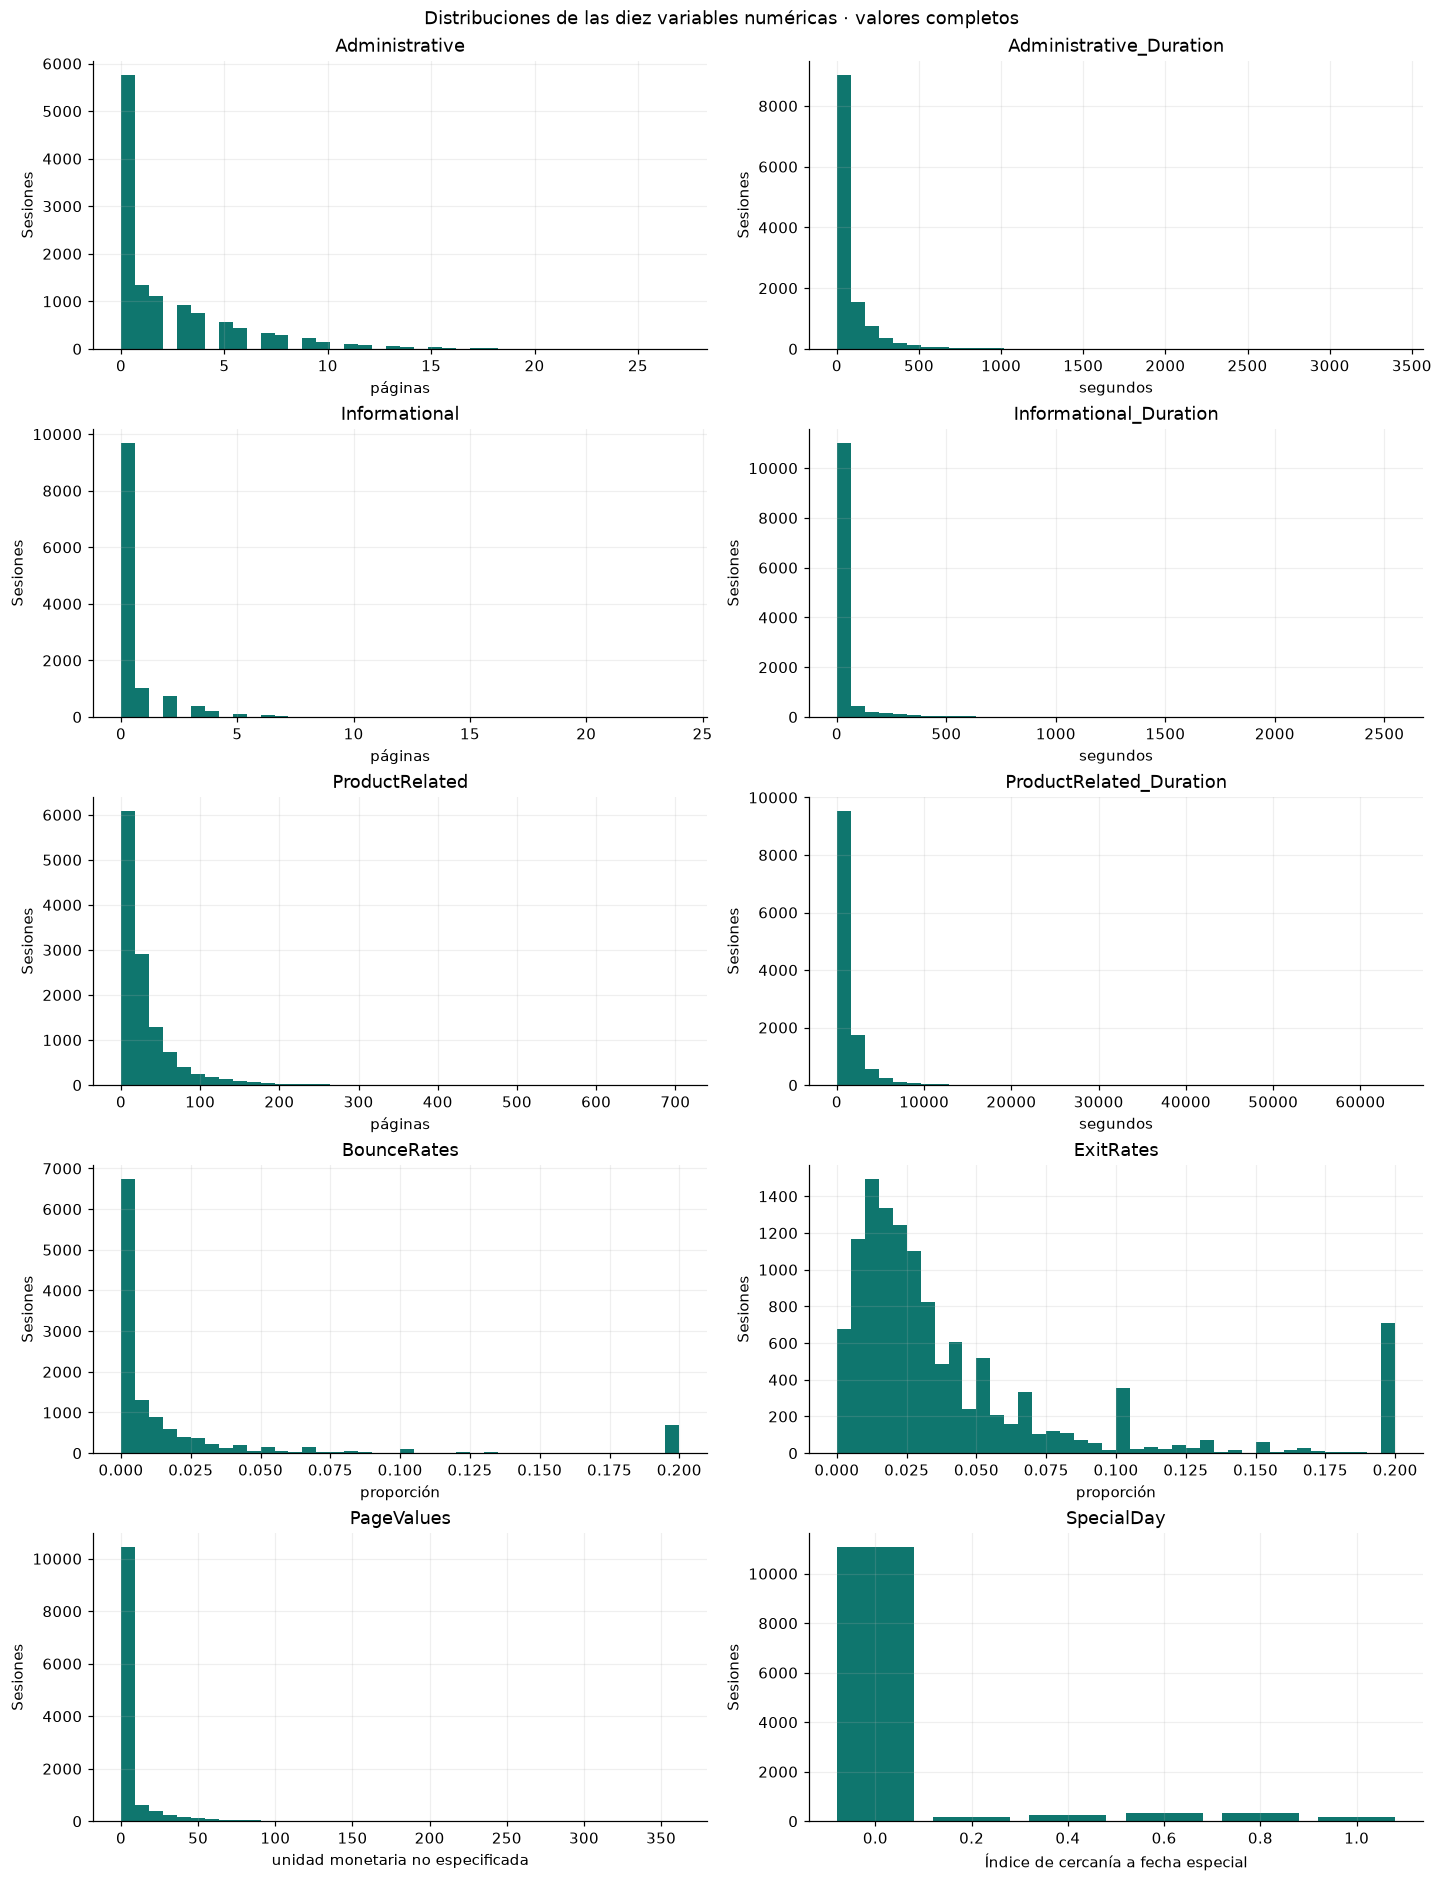

**Figura 1.** Distribuciones completas de las diez variables numéricas, con unidades originales.

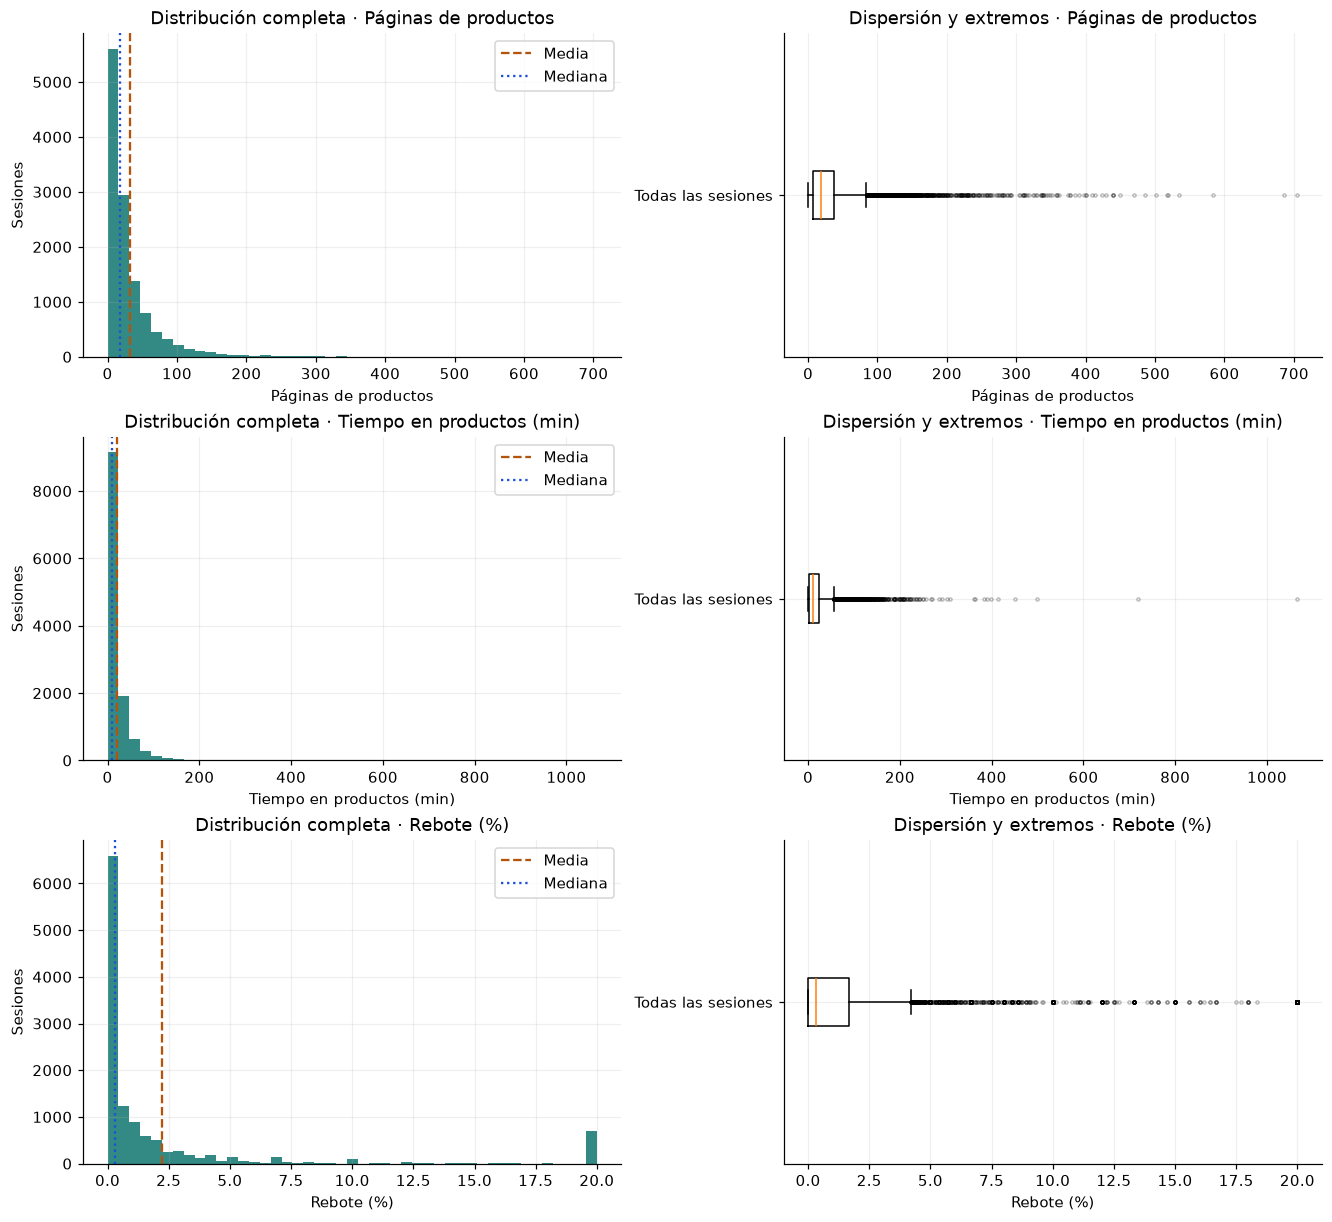

**Figura 2.** Histogramas y boxplots de las variables principales; las medias y medianas se indican en las distribuciones.

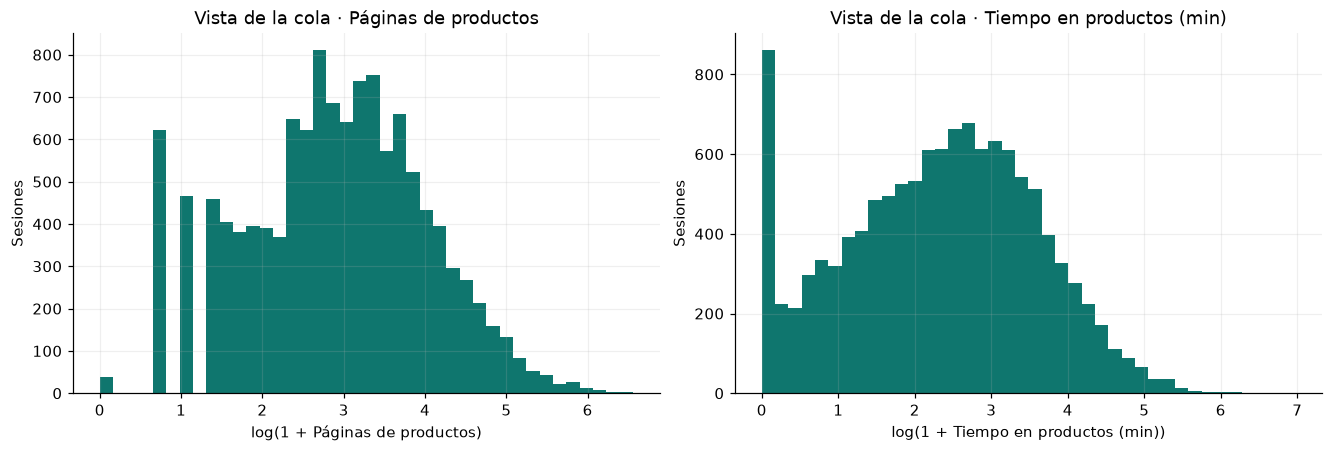

**Figura 3.** Distribuciones de páginas y minutos en escala log(1 + valor), conservando ceros.

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(13, 17), constrained_layout=True)
for ax, c in zip(axes.flat, NUMERICAS):
    valores = df[c]
    if c == 'SpecialDay':
        frecuencias_indice = valores.value_counts().sort_index()
        ax.bar(frecuencias_indice.index.astype(str), frecuencias_indice.values, color=COLORES[1])
        ax.set_xlabel('Índice de cercanía a fecha especial')
    else:
        ax.hist(valores, bins=40, color=COLORES[1])
        unidad = diccionario.set_index('Variable').loc[c, 'Unidad']
        ax.set_xlabel(unidad)
    ax.set(title=c, ylabel='Sesiones')
fig.suptitle('Distribuciones de las diez variables numéricas · valores completos')
plt.show()
display(Markdown('**Figura 1.** Distribuciones completas de las diez variables numéricas, con unidades originales.'))

fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
for fila, c in enumerate(PRINCIPALES):
    valores = df[c]*FACTORES[c]
    axes[fila, 0].hist(valores, bins=45, color=COLORES[1], alpha=.85)
    axes[fila, 0].axvline(valores.mean(), color='#b45309', linestyle='--', label='Media')
    axes[fila, 0].axvline(valores.median(), color='#1d4ed8', linestyle=':', label='Mediana')
    axes[fila, 0].set(title=f'Distribución completa · {ETIQUETAS[c]}',
                      xlabel=ETIQUETAS[c], ylabel='Sesiones')
    axes[fila, 0].legend()
    axes[fila, 1].boxplot(valores, orientation='horizontal', tick_labels=['Todas las sesiones'],
                         flierprops={'markersize': 2, 'alpha': .25})
    axes[fila, 1].set(title=f'Dispersión y extremos · {ETIQUETAS[c]}', xlabel=ETIQUETAS[c])
plt.show()
display(Markdown('**Figura 2.** Histogramas y boxplots de las variables principales; las medias y medianas se indican en las distribuciones.'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, c in zip(axes, PRINCIPALES[:2]):
    valores = df[c]*FACTORES[c]
    ax.hist(np.log1p(valores), bins=40, color=COLORES[1])
    ax.set(title=f'Vista de la cola · {ETIQUETAS[c]}',
           xlabel=f'log(1 + {ETIQUETAS[c]})', ylabel='Sesiones')
plt.show()
display(Markdown('**Figura 3.** Distribuciones de páginas y minutos en escala log(1 + valor), conservando ceros.'))

In [8]:
for c in PRINCIPALES:
    v = df[c]*FACTORES[c]
    display(Markdown(f'**{ETIQUETAS[c]}:** media **{numero(v.mean())}**, mediana '
                     f'**{numero(v.median())}** y desviación estándar **{numero(v.std())}**. '
                     f'La asimetría es **{numero(df[c].skew())}**; la distancia entre media y mediana '
                     'muestra por qué conviene presentar ambas medidas.'))
display(Markdown(f"""
**Extremos y medición.** La duración máxima en páginas de productos es
**{numero(df.ProductRelated_Duration.max()/3600)} horas**. Que el archivo original contenga
este valor no demuestra que una persona estuviera mirando activamente productos durante
todo ese tiempo. Se conserva y se informa como limitación de la medición.

La regla de 1,5 IQR marca observaciones para investigar, no errores que deban borrarse.
Si el IQR es cero, como puede ocurrir en variables con muchos ceros, la regla tiene utilidad
limitada. Las vistas logarítmicas ayudan a ver la cola; **no se transforman los datos usados
para estimar las medias ni se ocultan observaciones**.
"""))

**Páginas de productos:** media **31,73**, mediana **18,00** y desviación estándar **44,48**. La asimetría es **4,34**; la distancia entre media y mediana muestra por qué conviene presentar ambas medidas.

**Tiempo en productos (min):** media **19,91**, mediana **9,98** y desviación estándar **31,89**. La asimetría es **7,26**; la distancia entre media y mediana muestra por qué conviene presentar ambas medidas.

**Rebote (%):** media **2,22**, mediana **0,31** y desviación estándar **4,85**. La asimetría es **2,95**; la distancia entre media y mediana muestra por qué conviene presentar ambas medidas.


**Extremos y medición.** La duración máxima en páginas de productos es
**17,77 horas**. Que el archivo original contenga
este valor no demuestra que una persona estuviera mirando activamente productos durante
todo ese tiempo. Se conserva y se informa como limitación de la medición.

La regla de 1,5 IQR marca observaciones para investigar, no errores que deban borrarse.
Si el IQR es cero, como puede ocurrir en variables con muchos ceros, la regla tiene utilidad
limitada. Las vistas logarítmicas ayudan a ver la cola; **no se transforman los datos usados
para estimar las medias ni se ocultan observaciones**.


### 5.2 Variables categóricas

Se presentan conteos y porcentajes sobre todas las sesiones para cada categoría.
En los gráficos, los meses se ordenan cronológicamente; no aparecen meses sin registros.
Los números de códigos se muestran solo como etiquetas.

**Month**

,frecuencia,porcentaje
Month,,
Feb,184,"1,4923"
Mar,1907,"15,4663"
May,3364,"27,2830"
June,288,"2,3358"
Jul,432,"3,5036"
Aug,433,"3,5118"
Sep,448,"3,6334"
Oct,549,"4,4526"
Nov,2998,"24,3147"


**OperatingSystems**

,frecuencia,porcentaje
OperatingSystems,,
1,2585,"20,9651"
2,6601,"53,5361"
3,2555,"20,7218"
4,478,"3,8767"
5,6,"0,0487"
6,19,"0,1541"
7,7,"0,0568"
8,79,"0,6407"


**Browser**

...

,frecuencia,porcentaje
VisitorType,,
Returning_Visitor,10551,"85,5718"
New_Visitor,1694,"13,7388"
Other,85,"0,6894"


**Weekend**

,frecuencia,porcentaje
Weekend,,
False,9462,"76,7397"
True,2868,"23,2603"


**Revenue**

,frecuencia,porcentaje
Revenue,,
False,10422,"84,5255"
True,1908,"15,4745"


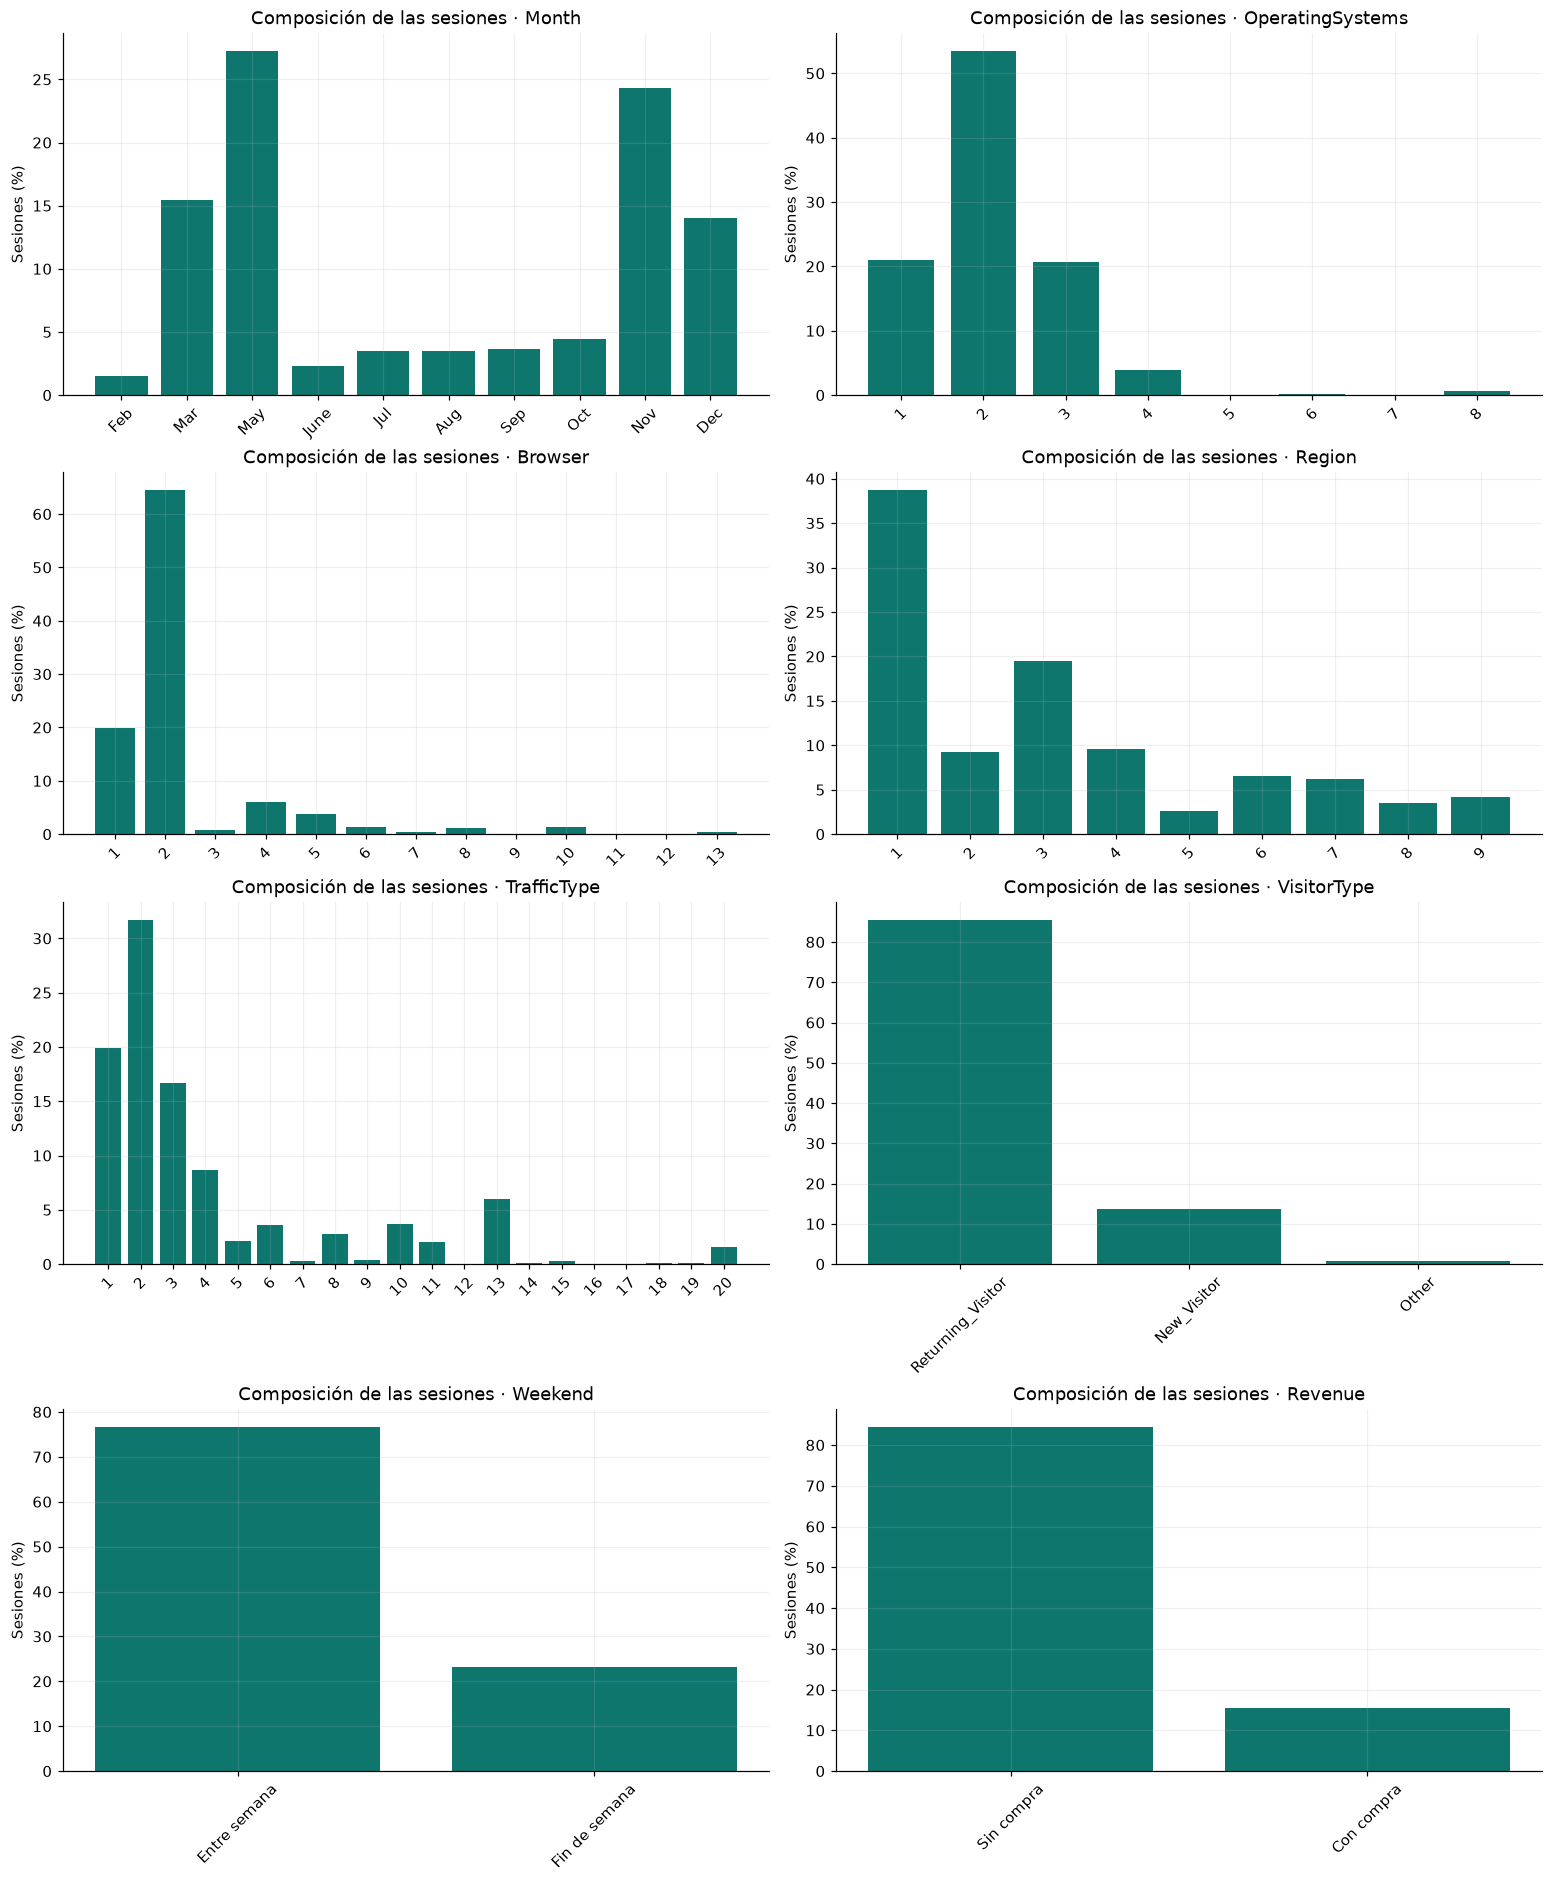

**Figura 4.** Composición porcentual de las sesiones en las ocho variables categóricas.


**Compra/no compra:** 1,908 de 12,330 sesiones terminan en compra
(**15,47 %**); 10,422 no lo hacen.
Por ello, contar compras por categoría sin considerar su tamaño puede inducir a error.
Los códigos de categorías pequeñas requieren especial cautela al interpretar porcentajes.


In [9]:
frecuencias = {}
for c in CATEGORICAS:
    conteos = df[c].value_counts(dropna=False)
    if c == 'Month':
        conteos = conteos.reindex([m for m in MESES if m in conteos.index])
    elif c in ['OperatingSystems', 'Browser', 'Region', 'TrafficType']:
        conteos = conteos.sort_index()
    tabla = pd.DataFrame({'frecuencia': conteos, 'porcentaje': conteos/len(df)*100})
    tabla.index.name = c
    frecuencias[c] = tabla
    display(Markdown(f'**{c}**'))
    display(tabla)

fig, axes = plt.subplots(4, 2, figsize=(14, 17), constrained_layout=True)
for ax, c in zip(axes.flat, CATEGORICAS):
    tabla = frecuencias[c]
    etiquetas = [str(v) for v in tabla.index]
    if c == 'Revenue':
        etiquetas = ['Con compra' if v else 'Sin compra' for v in tabla.index]
    if c == 'Weekend':
        etiquetas = ['Fin de semana' if v else 'Entre semana' for v in tabla.index]
    ax.bar(etiquetas, tabla.porcentaje, color=COLORES[1])
    ax.set(title=f'Composición de las sesiones · {c}', ylabel='Sesiones (%)')
    ax.tick_params(axis='x', rotation=45)
plt.show()
display(Markdown('**Figura 4.** Composición porcentual de las sesiones en las ocho variables categóricas.'))

n_compra = int(df.Revenue.sum())
porcentaje_compra = df.Revenue.mean()*100
display(Markdown(f"""
**Compra/no compra:** {n_compra:,} de {len(df):,} sesiones terminan en compra
(**{numero(porcentaje_compra)} %**); {len(df)-n_compra:,} no lo hacen.
Por ello, contar compras por categoría sin considerar su tamaño puede inducir a error.
Los códigos de categorías pequeñas requieren especial cautela al interpretar porcentajes.
"""))

## 6. Análisis bivariado
### 6.1 Comparación de navegación según compra

Cada porcentaje o promedio usa como denominador las sesiones de su propio grupo.
Las comparaciones iniciales son descriptivas; los contrastes de medias se desarrollan en la sección 8.

**Tabla 3. Navegación por resultado de compra**

,variable,grupo,n,media,mediana,desviación_estándar
0,Páginas de productos,Sin compra,10.422,"28,715","16,000","40,745"
1,Páginas de productos,Con compra,1.908,"48,210","29,000","58,267"
2,Tiempo en productos (min),Sin compra,10.422,"17,833","8,503","30,063"
3,Tiempo en productos (min),Con compra,1.908,"31,270","18,498","38,537"
4,Rebote (%),Sin compra,10.422,"2,532","0,426","5,188"
5,Rebote (%),Con compra,1.908,"0,512","0,000","1,218"
6,Salida (%),Sin compra,10.422,"4,738","2,857","5,123"
7,Salida (%),Con compra,1.908,"1,956","1,600","1,646"


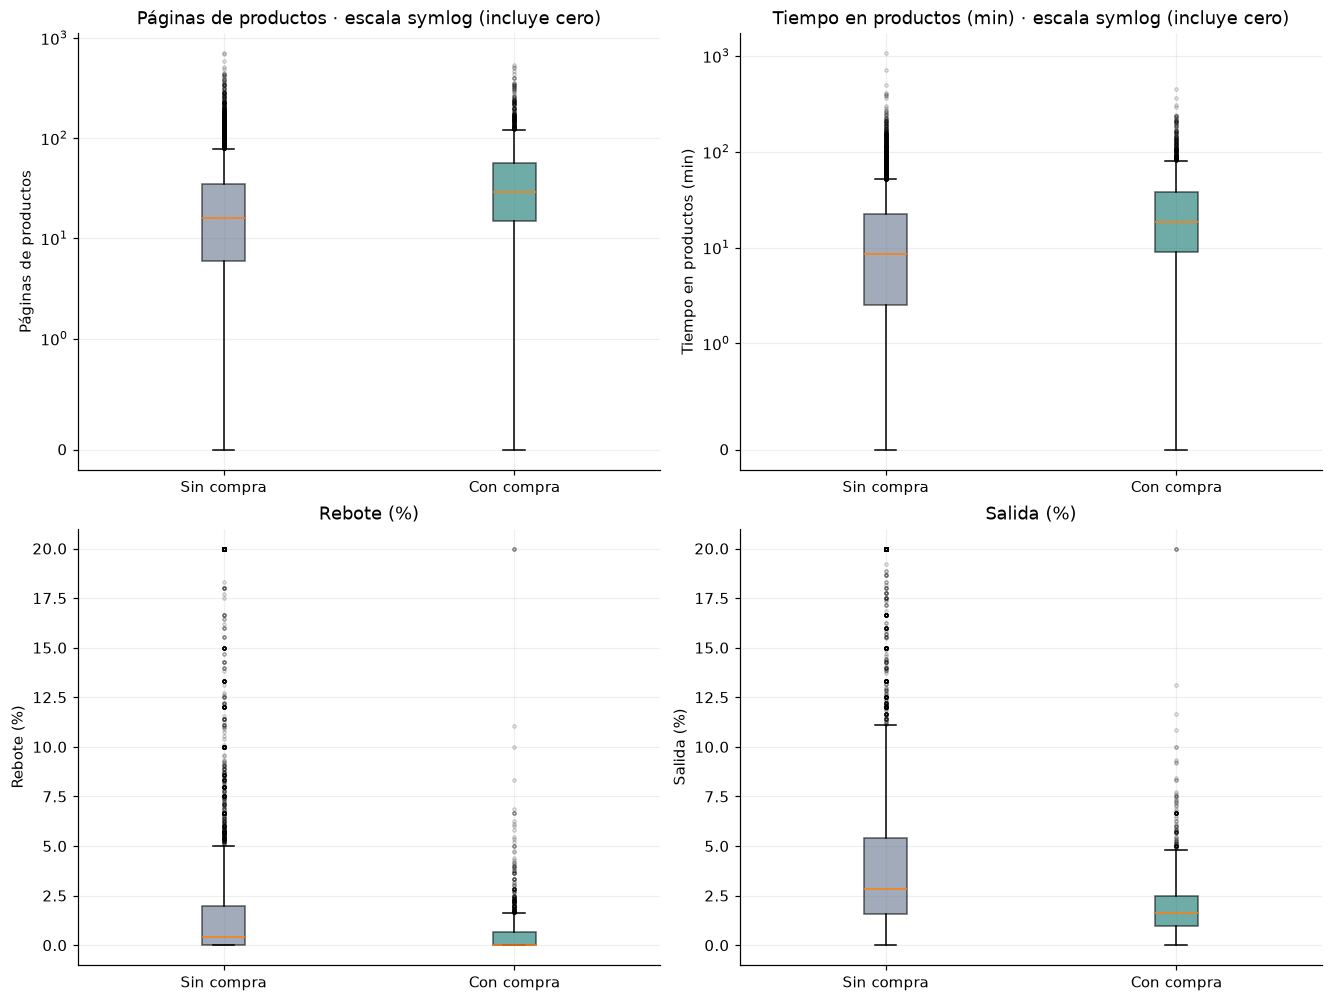

**Figura 5.** Comparaciones de navegación por compra; páginas y duración usan escala symlog para incluir cero y colas.

**Páginas de productos:** promedio con compra = **48,21**; sin compra = **28,71**. Esta comparación describe una asociación, sin establecer su dirección causal.

**Tiempo en productos (min):** promedio con compra = **31,27**; sin compra = **17,83**. Esta comparación describe una asociación, sin establecer su dirección causal.

**Rebote (%):** promedio con compra = **0,51**; sin compra = **2,53**. Esta comparación describe una asociación, sin establecer su dirección causal.

**Salida (%):** promedio con compra = **1,96**; sin compra = **4,74**. Esta comparación describe una asociación, sin establecer su dirección causal.

In [10]:
comparacion = df.groupby('Revenue')[PRINCIPALES + ['ExitRates']].agg(['count', 'mean', 'median', 'std'])
comparacion.index = ['Sin compra' if not v else 'Con compra' for v in comparacion.index]
comparacion_lectura=[]
for c in PRINCIPALES+['ExitRates']:
    for g in [False,True]:
        x=df.loc[df.Revenue==g,c]*FACTORES[c]
        comparacion_lectura.append({'variable':ETIQUETAS[c],
                                   'grupo':'Con compra' if g else 'Sin compra',
                                   'n':len(x),'media':x.mean(),'mediana':x.median(),
                                   'desviación_estándar':x.std()})
mostrar_tabla(pd.DataFrame(comparacion_lectura),'Navegación por resultado de compra',
              {'n':lambda x:numero(x,0)})

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for ax, c in zip(axes.flat, PRINCIPALES+['ExitRates']):
    grupos = [df.loc[df.Revenue==g, c]*FACTORES[c] for g in [False, True]]
    cajas = ax.boxplot(grupos, tick_labels=['Sin compra', 'Con compra'], patch_artist=True,
                       flierprops={'markersize': 2, 'alpha': .2})
    for caja, color in zip(cajas['boxes'], COLORES):
        caja.set_facecolor(color); caja.set_alpha(.6)
    if c in PRINCIPALES[:2]:
        ax.set_yscale('symlog', linthresh=1)
        ax.set_title(f'{ETIQUETAS[c]} · escala symlog (incluye cero)')
    else:
        ax.set_title(ETIQUETAS[c])
    ax.set_ylabel(ETIQUETAS[c])
plt.show()
display(Markdown('**Figura 5.** Comparaciones de navegación por compra; páginas y duración usan escala symlog para incluir cero y colas.'))

for c in PRINCIPALES+['ExitRates']:
    media_no = df.loc[~df.Revenue, c].mean()*FACTORES[c]
    media_si = df.loc[df.Revenue, c].mean()*FACTORES[c]
    display(Markdown(f'**{ETIQUETAS[c]}:** promedio con compra = **{numero(media_si)}**; '
                     f'sin compra = **{numero(media_no)}**. Esta comparación describe una asociación, '
                     'sin establecer su dirección causal.'))

### 6.2 Relaciones entre variables numéricas

Se usa **Spearman** para describir asociaciones monótonas por rangos, dado que las variables
presentan asimetría y extremos. No se interpretan correlaciones como causalidad ni se
incluyen códigos de categorías en la matriz. El mapa muestra coeficientes descriptivos,
sin contrastes múltiples de significancia.

,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
ProductRelated,"1,0000","0,8827","-0,0523","-0,5189"
ProductRelated_Duration,"0,8827","1,0000","-0,0798","-0,4769"
BounceRates,"-0,0523","-0,0798","1,0000","0,6023"
ExitRates,"-0,5189","-0,4769","0,6023","1,0000"


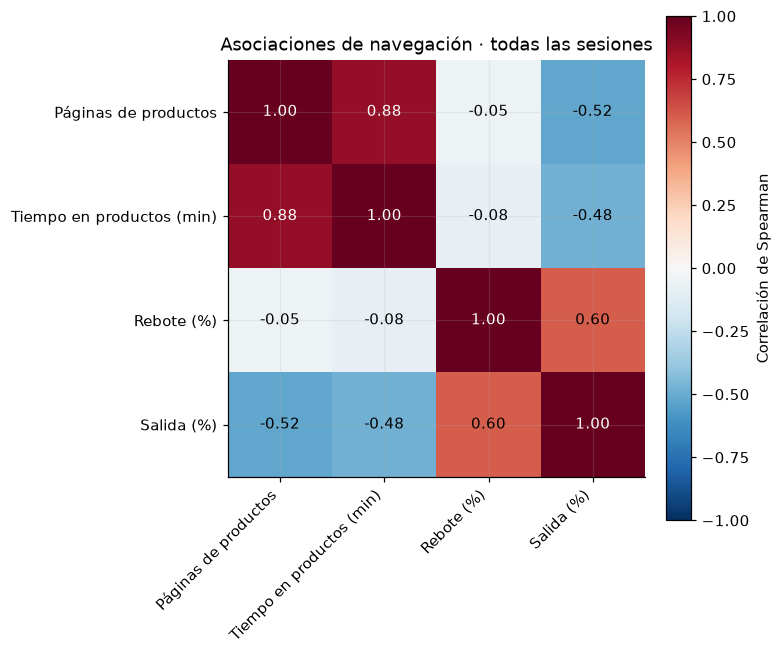

**Figura 6.** Correlaciones descriptivas de Spearman calculadas con todas las sesiones.

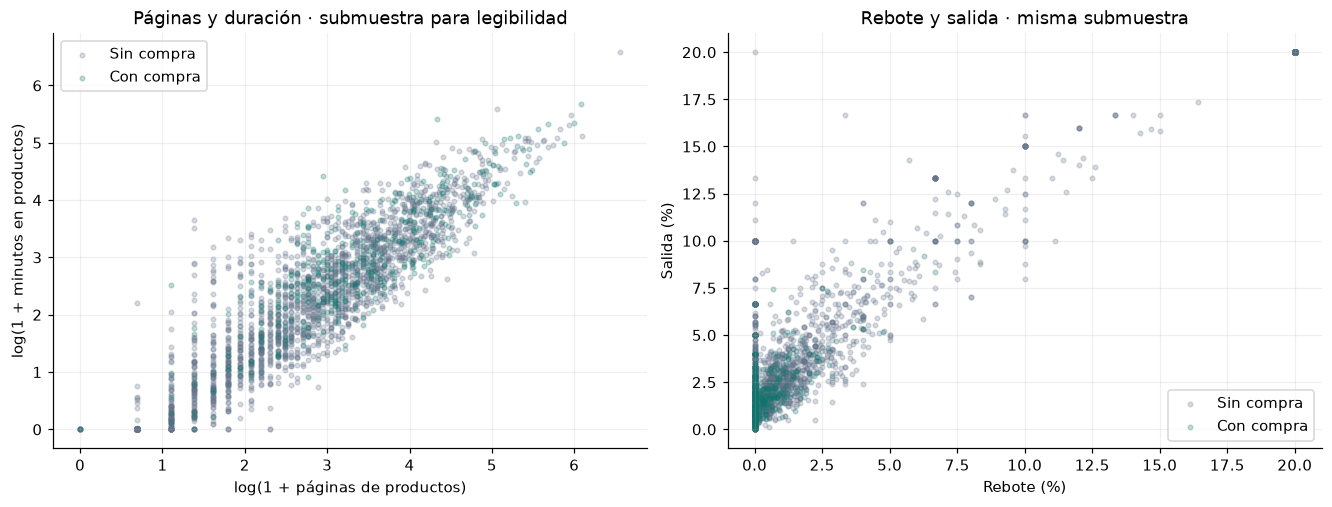

**Figura 7.** Relaciones de navegación en una submuestra fija de 2.500 sesiones, usada solo para legibilidad.


La asociación por rangos entre páginas de productos y duración es
**0,883**; entre rebote y salida,
**0,602**. No son medidas independientes de navegación.
La submuestra solo se usa para dibujar: las tablas, correlaciones y pruebas utilizan todas las sesiones.


In [11]:
CORRELACION = ['ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']
corr = df[CORRELACION].corr(method='spearman')
display(corr)
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(4), [ETIQUETAS[c] for c in CORRELACION], rotation=45, ha='right')
ax.set_yticks(range(4), [ETIQUETAS[c] for c in CORRELACION])
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i,j])>.7 else 'black')
fig.colorbar(im, ax=ax, label='Correlación de Spearman')
ax.set_title('Asociaciones de navegación · todas las sesiones')
plt.show()
display(Markdown('**Figura 6.** Correlaciones descriptivas de Spearman calculadas con todas las sesiones.'))

muestra_grafico = df.sample(n=min(2500, len(df)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for g, nombre, color in [(False, 'Sin compra', COLORES[0]), (True, 'Con compra', COLORES[1])]:
    s = muestra_grafico.loc[muestra_grafico.Revenue==g]
    axes[0].scatter(np.log1p(s.ProductRelated), np.log1p(s.ProductRelated_Duration/60),
                    s=9, alpha=.25, color=color, label=nombre)
    axes[1].scatter(s.BounceRates*100, s.ExitRates*100, s=9, alpha=.25, color=color, label=nombre)
axes[0].set(title='Páginas y duración · submuestra para legibilidad',
            xlabel='log(1 + páginas de productos)', ylabel='log(1 + minutos en productos)')
axes[1].set(title='Rebote y salida · misma submuestra', xlabel='Rebote (%)', ylabel='Salida (%)')
for ax in axes: ax.legend()
plt.show()
display(Markdown('**Figura 7.** Relaciones de navegación en una submuestra fija de 2.500 sesiones, usada solo para legibilidad.'))
display(Markdown(f"""
La asociación por rangos entre páginas de productos y duración es
**{numero(corr.loc['ProductRelated','ProductRelated_Duration'],3)}**; entre rebote y salida,
**{numero(corr.loc['BounceRates','ExitRates'],3)}**. No son medidas independientes de navegación.
La submuestra solo se usa para dibujar: las tablas, correlaciones y pruebas utilizan todas las sesiones.
"""))

### 6.3 Proporción de compra por categorías

Se distingue **composición** (cuántas sesiones pertenecen a una categoría) de
**conversión observada** (qué proporción compra dentro de ella). Esto evita confundir
un grupo numeroso con uno que tenga una mayor proporción de compras.

**Compra dentro de cada categoría de VisitorType**

,sesiones,compras,sin_compra,porcentaje_compra
VisitorType,,,,
New_Visitor,1694,422,1272,"24,9115"
Other,85,16,69,"18,8235"
Returning_Visitor,10551,1470,9081,"13,9323"


**Compra dentro de cada categoría de Month**

,sesiones,compras,sin_compra,porcentaje_compra
Month,,,,
Feb,184,3,181,"1,6304"
Mar,1907,192,1715,"10,0682"
May,3364,365,2999,"10,8502"
June,288,29,259,"10,0694"
Jul,432,66,366,"15,2778"
Aug,433,76,357,"17,5520"
Sep,448,86,362,"19,1964"
Oct,549,115,434,"20,9472"
Nov,2998,760,2238,"25,3502"


**Compra dentro de cada categoría de Weekend**

,sesiones,compras,sin_compra,porcentaje_compra
Weekend,,,,
False,9462,1409,8053,"14,8911"
True,2868,499,2369,"17,3989"


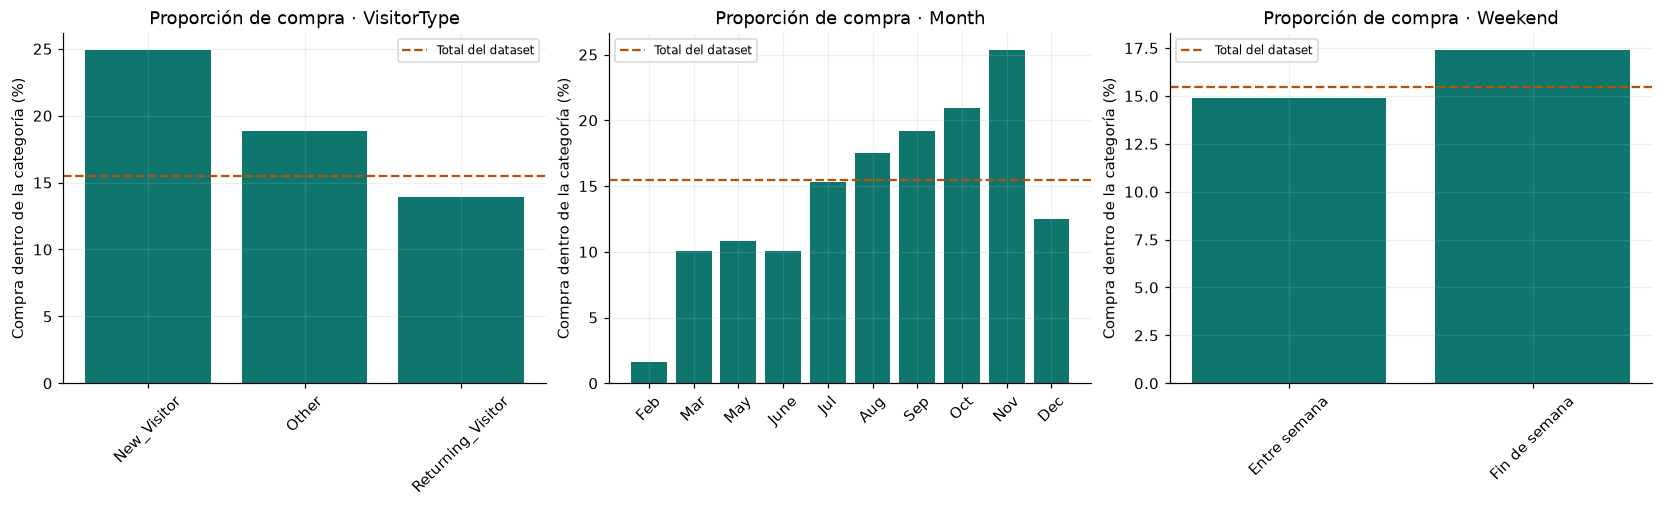

**Figura 8.** Proporción de compra dentro de cada categoría; la línea indica la proporción global.


Los visitantes nuevos tienen una proporción de compra de
**24,91 %**, frente a
**13,93 %** en recurrentes.
Esto no demuestra que ser nuevo provoque más compras: pueden intervenir fuente de tráfico,
campañas y otras características. Los meses no tienen igual cantidad de sesiones y faltan
enero y abril; estos porcentajes no describen una serie anual completa ni una tendencia causal.


In [12]:
conversion = {}
for c in ['VisitorType', 'Month', 'Weekend']:
    tabla = df.groupby(c, observed=True)['Revenue'].agg(sesiones='size', compras='sum')
    tabla['sin_compra'] = tabla.sesiones-tabla.compras
    tabla['porcentaje_compra'] = tabla.compras/tabla.sesiones*100
    if c=='Month': tabla=tabla.reindex([m for m in MESES if m in tabla.index])
    conversion[c]=tabla
    display(Markdown(f'**Compra dentro de cada categoría de {c}**'))
    display(tabla)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, c in zip(axes, conversion):
    tabla=conversion[c]
    etiquetas=[str(v) for v in tabla.index]
    if c=='Weekend': etiquetas=['Entre semana' if not v else 'Fin de semana' for v in tabla.index]
    ax.bar(etiquetas, tabla.porcentaje_compra, color=COLORES[1])
    ax.axhline(porcentaje_compra, color='#b45309', linestyle='--', label='Total del dataset')
    ax.set(title=f'Proporción de compra · {c}', ylabel='Compra dentro de la categoría (%)')
    ax.tick_params(axis='x', rotation=45); ax.legend(fontsize=8)
plt.show()
display(Markdown('**Figura 8.** Proporción de compra dentro de cada categoría; la línea indica la proporción global.'))
v=conversion['VisitorType']
display(Markdown(f"""
Los visitantes nuevos tienen una proporción de compra de
**{numero(v.loc['New_Visitor','porcentaje_compra'])} %**, frente a
**{numero(v.loc['Returning_Visitor','porcentaje_compra'])} %** en recurrentes.
Esto no demuestra que ser nuevo provoque más compras: pueden intervenir fuente de tráfico,
campañas y otras características. Los meses no tienen igual cantidad de sesiones y faltan
enero y abril; estos porcentajes no describen una serie anual completa ni una tendencia causal.
"""))

## 7. Estimación puntual e intervalos de confianza del 95 %

**Parámetros de interés:** las medias de páginas de productos, tiempo en esas páginas y
métrica de rebote de sesiones del proceso que generó estos datos. La media muestral estima
cada parámetro. No se generaliza automáticamente a todas las tiendas ni a períodos futuros.

Se calcula un IC aproximado para la media: **media ± t crítico × s/√n**.
Se usa t porque la desviación poblacional es desconocida. Las observaciones no son normales:
la aproximación de la media se apoya en el gran tamaño muestral y requiere independencia
razonable y varianza finita; el tamaño no corrige sesgo de selección ni problemas de medición.

**Interpretación:** si repitiéramos el procedimiento con muestras comparables bajo estos
supuestos, aproximadamente el 95 % de los intervalos cubriría el parámetro.
El intervalo no contiene al 95 % de las sesiones, ni expresa una probabilidad del 95 %
sobre un parámetro fijo en la interpretación frecuentista.

Como comprobación complementaria ante la asimetría, se presenta un IC bootstrap percentil
de la media con 2.000 remuestras, semilla fija y reemplazo. No añade información nueva
ni resuelve la representatividad. El IC t es el procedimiento principal y el bootstrap
permite comparar la sensibilidad al método de intervalo.

**Por qué estas tres variables:** ProductRelated describe la amplitud de exploración del
catálogo; ProductRelated_Duration, el tiempo registrado en esa exploración; BounceRates,
una métrica de rebote asociada a las páginas visitadas. Juntas cubren volumen, duración y
abandono, con interpretaciones distintas. El parámetro de BounceRates es la **media de esa
métrica entre sesiones**, no la proporción de sesiones sin compra ni la tasa global de rebote
reconstruida a partir de eventos individuales.

La población de referencia propuesta son **sesiones comparables del mismo sitio y proceso
de registro durante el contexto estudiado**. Es una referencia de trabajo: el CSV no documenta
un muestreo probabilístico que garantice representatividad. Las medias observadas describen
exactamente estos registros; la extensión de los IC a esa población está condicionada al
modelo de muestreo y a los supuestos, no es una generalización confirmada.

In [13]:
def intervalo_media(x, confianza=CONFIANZA):
    x=np.asarray(x, dtype=float)
    n=len(x); media=x.mean(); s=x.std(ddof=1); se=s/np.sqrt(n)
    critico=stats.t.ppf((1+confianza)/2, n-1)
    return n, media, s, se, media-critico*se, media+critico*se

def bootstrap_media(x, rng, b=2000, lote=25):
    x=np.asarray(x, dtype=float)
    medias=np.empty(b)
    for inicio in range(0, b, lote):
        cantidad=min(lote,b-inicio)
        indices=rng.integers(0,len(x),size=(cantidad,len(x)))
        medias[inicio:inicio+cantidad]=x[indices].mean(axis=1)
    return np.quantile(medias, [.025,.975])

rng=np.random.default_rng(SEED)
registros=[]
for c in PRINCIPALES:
    n,m,s,se,li,ls=intervalo_media(df[c])
    bli,bls=bootstrap_media(df[c],rng)
    registros.append({'variable':c,'n':n,'media':m,'desviación_estándar':s,'error_estándar':se,
                      'IC95_t_inferior':li,'IC95_t_superior':ls,
                      'IC95_bootstrap_inferior':bli,'IC95_bootstrap_superior':bls})
estimaciones=pd.DataFrame(registros).set_index('variable')
mostrar_tabla(estimaciones, 'Medias e intervalos del 95 % en unidades originales')

estimaciones_comunicacion=estimaciones.copy()
for c in PRINCIPALES:
    estimaciones_comunicacion.loc[c, estimaciones.columns.drop('n')]*=FACTORES[c]
estimaciones_comunicacion.index=[ETIQUETAS[c] for c in PRINCIPALES]
display(Markdown('**Mismos resultados en páginas, minutos y porcentaje de rebote:**'))
mostrar_tabla(estimaciones_comunicacion, 'Medias e intervalos en páginas, minutos y porcentaje de la métrica de rebote')

**Tabla 4. Medias e intervalos del 95 % en unidades originales**

,n,media,desviación_estándar,error_estándar,IC95_t_inferior,IC95_t_superior,IC95_bootstrap_inferior,IC95_bootstrap_superior
variable,,,,,,,,
ProductRelated,12.330,"31,731","44,476","0,401","30,946","32,517","30,917","32,544"
ProductRelated_Duration,12.330,"1.194,746","1.913,669","17,234","1.160,965","1.228,527","1.161,599","1.229,946"
BounceRates,12.330,"0,022","0,048","0,000","0,021","0,023","0,021","0,023"


**Mismos resultados en páginas, minutos y porcentaje de rebote:**

**Tabla 5. Medias e intervalos en páginas, minutos y porcentaje de la métrica de rebote**

,n,media,desviación_estándar,error_estándar,IC95_t_inferior,IC95_t_superior,IC95_bootstrap_inferior,IC95_bootstrap_superior
Páginas de productos,12.330,"31,731","44,476","0,401","30,946","32,517","30,917","32,544"
Tiempo en productos (min),12.330,"19,912","31,894","0,287","19,349","20,475","19,360","20,499"
Rebote (%),12.330,"2,219","4,849","0,044","2,134","2,305","2,137","2,308"


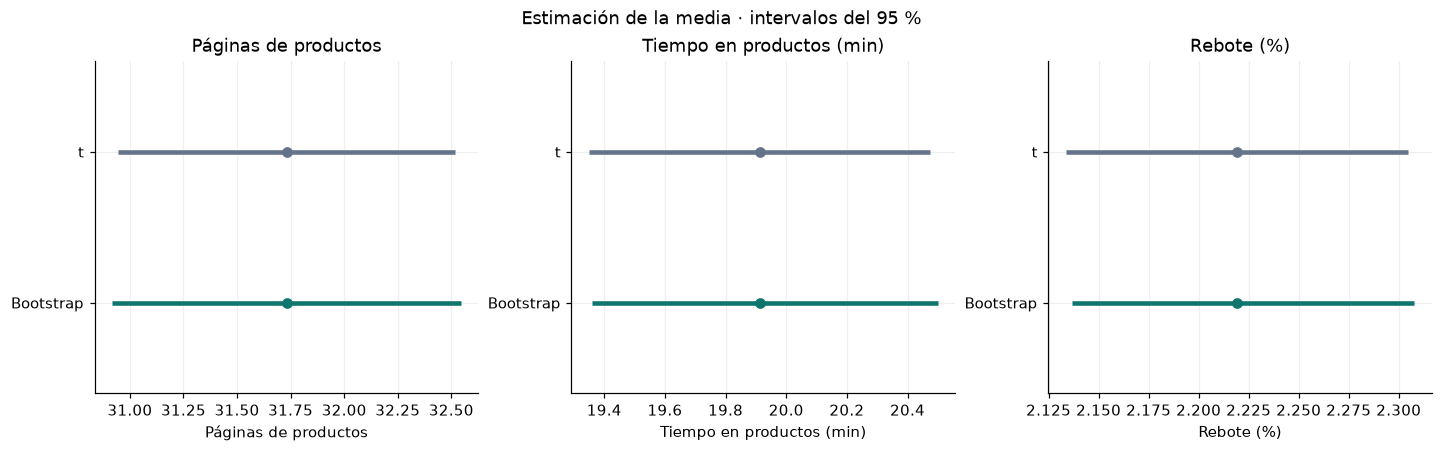

**Figura 9.** Medias e intervalos del 95 % mediante t y bootstrap, en unidades de comunicación.

**Páginas de productos:** media **31,731**, IC t del 95 % **[30,946; 32,517]**; mediana **18,000**. El intervalo estima el promedio de páginas visitadas. No significa que una sesión típica visite ese rango de páginas; la mediana describe mejor el centro de la distribución asimétrica.

**Tiempo en productos (min):** media **19,912**, IC t del 95 % **[19,349; 20,475]**; mediana **9,982**. El intervalo estima el tiempo promedio registrado en páginas de productos. No representa atención activa comprobada ni el rango donde cae el 95 % de las sesiones. La diferencia respecto de la mediana muestra el efecto de la cola larga.

**Rebote (%):** media **2,219**, IC t del 95 % **[2,134; 2,305]**; mediana **0,311**. El intervalo estima el promedio de la métrica de rebote asociada a las sesiones. No es la proporción de usuarios que abandonaron sin comprar ni la probabilidad de compra.

**Tabla 6. Comparación efectiva entre IC t y bootstrap**

,variable,amplitud_t,amplitud_bootstrap,cambio_amplitud_%,máxima_diferencia_entre_límites
0,Páginas de productos,"1,570","1,627","3,636","0,029"
1,Tiempo en productos (min),"1,126","1,139","1,161","0,024"
2,Rebote (%),"0,171","0,171","-0,037","0,003"


**Páginas de productos:** la amplitud bootstrap cambia **3,64 %** respecto de t; la mayor diferencia entre límites es **0,0293**, en las unidades del indicador.

**Tiempo en productos (min):** la amplitud bootstrap cambia **1,16 %** respecto de t; la mayor diferencia entre límites es **0,0236**, en las unidades del indicador.

**Rebote (%):** la amplitud bootstrap cambia **-0,04 %** respecto de t; la mayor diferencia entre límites es **0,0032**, en las unidades del indicador.

En esta ejecución los límites de ambos métodos son próximos y cuentan una historia similar sobre la incertidumbre de las medias. Es una comparación empírica, no un criterio universal de equivalencia. El bootstrap percentil también es aproximado y tiene variabilidad de remuestreo; la concordancia no valida representatividad, independencia ni medición.

In [14]:
fig, axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for ax,c in zip(axes,PRINCIPALES):
    r=estimaciones.loc[c]; factor=FACTORES[c]
    for y,prefijo,color in [(1,'IC95_t',COLORES[0]),(0,'IC95_bootstrap',COLORES[1])]:
        li=r[prefijo+'_inferior']*factor; ls=r[prefijo+'_superior']*factor
        ax.hlines(y,li,ls,color=color,linewidth=3)
        ax.plot(r['media']*factor,y,'o',color=color)
    ax.set_yticks([0,1],['Bootstrap','t'])
    ax.set(title=ETIQUETAS[c],xlabel=ETIQUETAS[c],ylim=(-.6,1.6))
fig.suptitle('Estimación de la media · intervalos del 95 %')
plt.show()
display(Markdown('**Figura 9.** Medias e intervalos del 95 % mediante t y bootstrap, en unidades de comunicación.'))
for c in PRINCIPALES:
    r=estimaciones.loc[c]; f=FACTORES[c]
    mediana=df[c].median()*f
    explicacion={
        'ProductRelated': 'El intervalo estima el promedio de páginas visitadas. No significa que una sesión típica visite ese rango de páginas; la mediana describe mejor el centro de la distribución asimétrica.',
        'ProductRelated_Duration': 'El intervalo estima el tiempo promedio registrado en páginas de productos. No representa atención activa comprobada ni el rango donde cae el 95 % de las sesiones. La diferencia respecto de la mediana muestra el efecto de la cola larga.',
        'BounceRates': 'El intervalo estima el promedio de la métrica de rebote asociada a las sesiones. No es la proporción de usuarios que abandonaron sin comprar ni la probabilidad de compra.'
    }[c]
    display(Markdown(f'**{ETIQUETAS[c]}:** media **{numero(r["media"]*f,3)}**, '
                     f'IC t del 95 % **[{numero(r["IC95_t_inferior"]*f,3)}; '
                     f'{numero(r["IC95_t_superior"]*f,3)}]**; mediana **{numero(mediana,3)}**. '
                     +explicacion))

comparacion_ic=[]
for c in PRINCIPALES:
    r=estimaciones.loc[c];f=FACTORES[c]
    ancho_t=(r.IC95_t_superior-r.IC95_t_inferior)*f
    ancho_b=(r.IC95_bootstrap_superior-r.IC95_bootstrap_inferior)*f
    desplazamiento=max(abs(r.IC95_t_inferior-r.IC95_bootstrap_inferior),
                       abs(r.IC95_t_superior-r.IC95_bootstrap_superior))*f
    comparacion_ic.append({'variable':ETIQUETAS[c],'amplitud_t':ancho_t,
                          'amplitud_bootstrap':ancho_b,
                          'cambio_amplitud_%':(ancho_b/ancho_t-1)*100,
                          'máxima_diferencia_entre_límites':desplazamiento})
mostrar_tabla(pd.DataFrame(comparacion_ic),'Comparación efectiva entre IC t y bootstrap')
for r in comparacion_ic:
    display(Markdown(f'**{r["variable"]}:** la amplitud bootstrap cambia '
                     f'**{numero(r["cambio_amplitud_%"])} %** respecto de t; '
                     f'la mayor diferencia entre límites es **{numero(r["máxima_diferencia_entre_límites"],4)}**, '
                     'en las unidades del indicador.'))
display(Markdown('En esta ejecución los límites de ambos métodos son próximos y cuentan una historia '
                 'similar sobre la incertidumbre de las medias. Es una comparación empírica, '
                 'no un criterio universal de equivalencia. El bootstrap percentil también es aproximado '
                 'y tiene variabilidad de remuestreo; la concordancia no valida representatividad, '
                 'independencia ni medición.'))

## 8. Pruebas de hipótesis y relevancia práctica

Se realizan **dos contrastes bilaterales** de medias de muestras independientes:

| Prueba | H₀ | H₁ |
|---|---|---|
| Páginas de productos | μ con compra = μ sin compra | Las medias son distintas |
| Duración en productos | μ con compra = μ sin compra | Las medias son distintas |

Se fija **α = 0,05** como umbral convencional para este avance académico, antes de ejecutar
los contrastes. No es una garantía de certeza ni implica que un valor p sea la probabilidad
de que H₀ sea verdadera. Como son dos preguntas relacionadas, se ajustan sus valores p
con **Holm** para controlar el error tipo I de la familia de dos contrastes.

### 8.1 Evaluación de supuestos y elección del método

- **Independencia:** la fuente describe usuarios diferentes, pero no es verificable totalmente
  con este CSV; pueden existir influencias compartidas. No se trata de datos pareados.
- **Distribución y extremos:** se evalúan tamaños, asimetría, boxplots y Q-Q plots por grupo.
  No se afirma normalidad porque haya muchas observaciones ni se usa una prueba de normalidad
  como decisión automática.
- **Varianzas:** se muestran desviaciones por grupo; se usa Welch para no imponer igualdad.
- **Aproximación de medias:** los tamaños de ambos grupos permiten una aproximación asintótica,
  condicionada a independencia y varianza finita; las colas fuertes justifican examinar sensibilidad.

Welch compara **medias**, no medianas. Un contraste por rangos respondería a otro estimando
y no sería un reemplazo automático solo por detectar asimetría.

,variable,grupo,n,media,mediana,desviación_estándar,asimetría,máximo
0,ProductRelated,Sin compra,10422,"28,7146","16,0000","40,7447","4,6941","705,0000"
1,ProductRelated,Con compra,1908,"48,2102","29,0000","58,2674","3,2594","534,0000"
2,ProductRelated_Duration,Sin compra,10422,"1.069,9878","510,1900","1.803,7978","8,8330","63.973,5222"
3,ProductRelated_Duration,Con compra,1908,"1.876,2096","1.109,9062","2.312,2144","3,3376","27.009,8594"


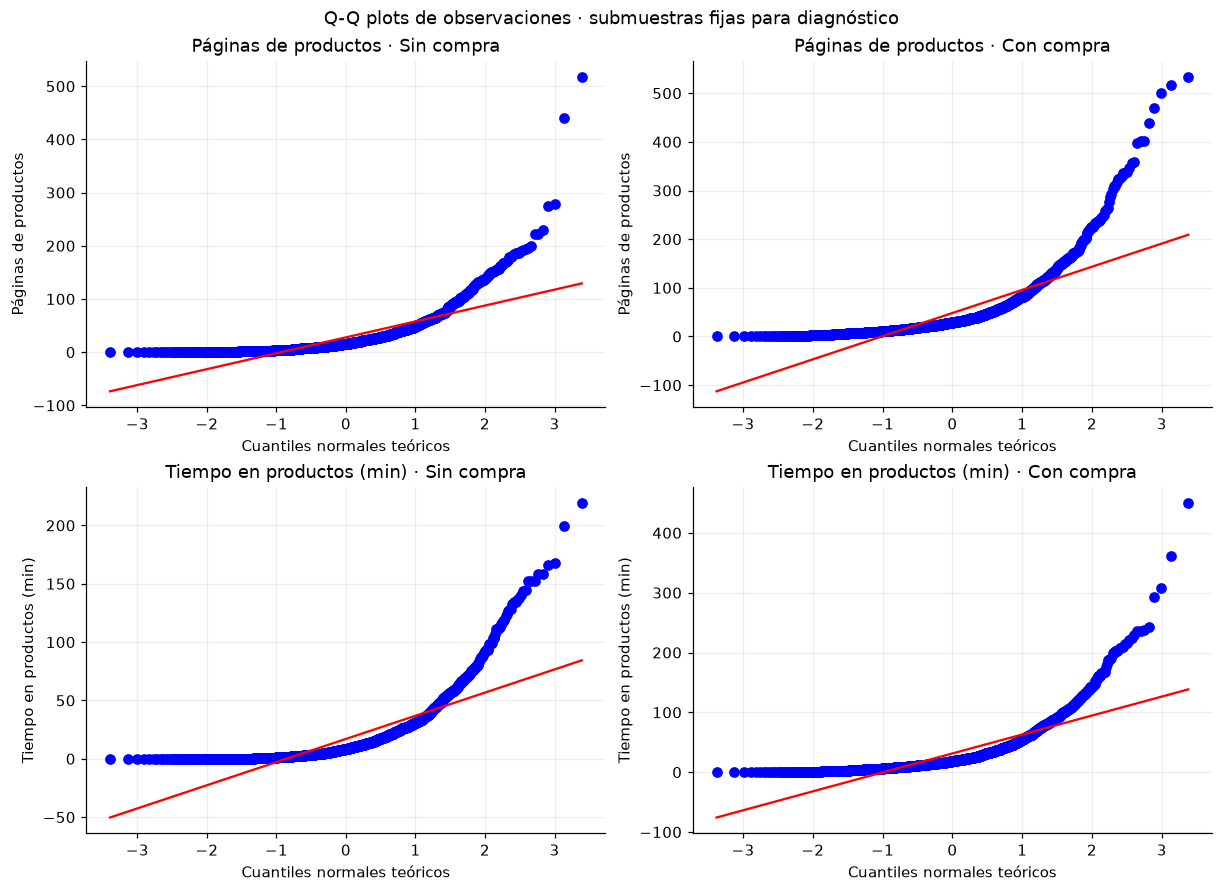

**Figura 10.** Q-Q plots por grupo sobre submuestras fijas: diagnóstico de distribución individual, no de normalidad de medias.

Los Q-Q plots muestran desviaciones de una distribución normal individual. Los contrastes posteriores son aproximaciones de la distribución de las medias, no una afirmación de que las observaciones originales sean normales.

In [15]:
diagnostico=[]
for c in PRINCIPALES[:2]:
    for g in [False,True]:
        x=df.loc[df.Revenue==g,c]
        diagnostico.append({'variable':c,'grupo':'Con compra' if g else 'Sin compra',
                            'n':len(x),'media':x.mean(),'mediana':x.median(),
                            'desviación_estándar':x.std(),'asimetría':x.skew(),
                            'máximo':x.max()})
display(pd.DataFrame(diagnostico))
fig,axes=plt.subplots(2,2,figsize=(11,8),constrained_layout=True)
for fila,c in enumerate(PRINCIPALES[:2]):
    for col,g in enumerate([False,True]):
        x=df.loc[df.Revenue==g,c]*FACTORES[c]
        x=x.sample(n=min(2000,len(x)),random_state=SEED)
        stats.probplot(x,dist='norm',plot=axes[fila,col])
        axes[fila,col].set(title=f'{ETIQUETAS[c]} · {"Con compra" if g else "Sin compra"}',
                           xlabel='Cuantiles normales teóricos',ylabel=ETIQUETAS[c])
fig.suptitle('Q-Q plots de observaciones · submuestras fijas para diagnóstico')
plt.show()
display(Markdown('**Figura 10.** Q-Q plots por grupo sobre submuestras fijas: diagnóstico de distribución individual, no de normalidad de medias.'))
display(Markdown('Los Q-Q plots muestran desviaciones de una distribución normal individual. '
                 'Los contrastes posteriores son aproximaciones de la distribución de las medias, '
                 'no una afirmación de que las observaciones originales sean normales.'))

In [16]:
def ajuste_holm(valores):
    p=np.asarray(valores,dtype=float); orden=np.argsort(p); m=len(p)
    ajustados_orden=np.minimum(1,np.maximum.accumulate((m-np.arange(m))*p[orden]))
    ajustados=np.empty(m); ajustados[orden]=ajustados_orden
    return ajustados

def contrastar_medias(datos):
    resultados=[]
    for c in PRINCIPALES[:2]:
        con=datos.loc[datos.Revenue,c].to_numpy()
        sin=datos.loc[~datos.Revenue,c].to_numpy()
        test=stats.ttest_ind(con,sin,equal_var=False,alternative='two-sided')
        ic=test.confidence_interval(confidence_level=CONFIANZA)
        resultados.append({'variable':c,'n_con_compra':len(con),'n_sin_compra':len(sin),
                            'media_con_compra':con.mean(),'media_sin_compra':sin.mean(),
                            'diferencia_con_menos_sin':con.mean()-sin.mean(),
                            'IC95_diferencia_inferior':ic.low,'IC95_diferencia_superior':ic.high,
                            't_Welch':test.statistic,'grados_libertad':test.df,'p_sin_ajuste':test.pvalue})
    salida=pd.DataFrame(resultados).set_index('variable')
    salida['p_Holm']=ajuste_holm(salida.p_sin_ajuste)
    salida['decisión_Holm']=np.where(salida.p_Holm<ALPHA,'Rechazar H₀','No rechazar H₀')
    return salida

pruebas=contrastar_medias(df)
display(pruebas.drop(columns=['p_sin_ajuste','p_Holm']))
display(pruebas[['p_sin_ajuste','p_Holm']].map(lambda p:f'{p:.3e}'))
display(Markdown('Los IC del 95 % de las diferencias son **individuales**, no intervalos simultáneos '
                 'ajustados por Holm. Las decisiones sobre la familia usan los valores p ajustados.'))

,n_con_compra,n_sin_compra,media_con_compra,media_sin_compra,diferencia_con_menos_sin,IC95_diferencia_inferior,IC95_diferencia_superior,t_Welch,grados_libertad,decisión_Holm
variable,,,,,,,,,,
ProductRelated,1908,10422,"48,2102","28,7146","19,4955","16,7651","22,2260","14,0017","2.260,3960",Rechazar H₀
ProductRelated_Duration,1908,10422,"1.876,2096","1.069,9878","806,2218","696,7886","915,6550","14,4470","2.350,2735",Rechazar H₀


,p_sin_ajuste,p_Holm
variable,,
ProductRelated,8.835e-43,8.835e-43
ProductRelated_Duration,2.174e-45,4.348e-45


Los IC del 95 % de las diferencias son **individuales**, no intervalos simultáneos ajustados por Holm. Las decisiones sobre la familia usan los valores p ajustados.

In [17]:
for c in PRINCIPALES[:2]:
    r=pruebas.loc[c]; f=FACTORES[c]
    display(Markdown(f"""
**{ETIQUETAS[c]}:** t de Welch = **{numero(r['t_Welch'],3)}**, grados de libertad =
**{numero(r['grados_libertad'],1)}**, p sin ajuste = **{r['p_sin_ajuste']:.3e}** y
p ajustado por Holm = **{r['p_Holm']:.3e}**. Decisión con α = {ALPHA}: **{r['decisión_Holm']}**.

La diferencia estimada (con compra menos sin compra) es **{numero(r['diferencia_con_menos_sin']*f)}**,
con IC individual del 95 % **[{numero(r['IC95_diferencia_inferior']*f)};
{numero(r['IC95_diferencia_superior']*f)}]**, en las unidades del título.
La magnitud se interpreta junto con el problema: el dataset no proporciona un umbral de
relevancia empresarial, por lo que no se afirma que la diferencia garantice una mejora del negocio.
"""))
display(Markdown('**Implicancia preliminar:** las diferencias pueden orientar el estudio de cómo '
                 'se exploran productos. No justifican recomendar que se obligue a los usuarios '
                 'a visitar más páginas o permanecer más tiempo: también podría aumentar la fricción.'))


**Páginas de productos:** t de Welch = **14,002**, grados de libertad =
**2.260,4**, p sin ajuste = **8.835e-43** y
p ajustado por Holm = **8.835e-43**. Decisión con α = 0.05: **Rechazar H₀**.

La diferencia estimada (con compra menos sin compra) es **19,50**,
con IC individual del 95 % **[16,77;
22,23]**, en las unidades del título.
La magnitud se interpreta junto con el problema: el dataset no proporciona un umbral de
relevancia empresarial, por lo que no se afirma que la diferencia garantice una mejora del negocio.



**Tiempo en productos (min):** t de Welch = **14,447**, grados de libertad =
**2.350,3**, p sin ajuste = **2.174e-45** y
p ajustado por Holm = **4.348e-45**. Decisión con α = 0.05: **Rechazar H₀**.

La diferencia estimada (con compra menos sin compra) es **13,44**,
con IC individual del 95 % **[11,61;
15,26]**, en las unidades del título.
La magnitud se interpreta junto con el problema: el dataset no proporciona un umbral de
relevancia empresarial, por lo que no se afirma que la diferencia garantice una mejora del negocio.


**Implicancia preliminar:** las diferencias pueden orientar el estudio de cómo se exploran productos. No justifican recomendar que se obligue a los usuarios a visitar más páginas o permanecer más tiempo: también podría aumentar la fricción.

### 8.2 Sensibilidad a filas idénticas

Se repiten las estimaciones y los dos contrastes excluyendo las filas idénticas posteriores
a la primera. Es un escenario alternativo: no una corrección confirmada. Cada conjunto de
dos contrastes usa Holm por separado; el escenario no se usa para seleccionar el resultado
más favorable. Esta comparación evalúa exclusivamente la decisión sobre filas idénticas,
no todas las fuentes de incertidumbre ni la influencia de valores extremos.

In [18]:
df_sin_identicas=df.drop_duplicates().copy()
pruebas_sensibilidad=contrastar_medias(df_sin_identicas)
sensibilidad=[]
for c in PRINCIPALES:
    principal=df[c].mean(); alternativa=df_sin_identicas[c].mean()
    sensibilidad.append({'variable':c,'media_todas':principal,'media_sin_identicas':alternativa,
                         'cambio_relativo_porcentaje':(alternativa/principal-1)*100 if principal else np.nan})
display(pd.DataFrame(sensibilidad).set_index('variable'))
display(pruebas_sensibilidad[['n_con_compra','n_sin_compra','diferencia_con_menos_sin',
                              'IC95_diferencia_inferior','IC95_diferencia_superior','decisión_Holm']])
display(pruebas_sensibilidad[['p_sin_ajuste','p_Holm']].map(lambda p:f'{p:.3e}'))
coinciden=(pruebas['decisión_Holm']==pruebas_sensibilidad['decisión_Holm']).all()
display(Markdown(f'Se pasa de **{len(df):,}** a **{len(df_sin_identicas):,}** sesiones. '
                 f'Las decisiones de las dos pruebas **{"se mantienen" if coinciden else "cambian"}**. '
                 'También deben revisarse los cambios en magnitud: mantener una decisión no '
                 'significa que los resultados sean idénticos ni resuelve la falta de identificadores.'))

rebote_todas=df.BounceRates.mean()*100
rebote_sin=df_sin_identicas.BounceRates.mean()*100
cambio_rebote=(rebote_sin/rebote_todas-1)*100
display(Markdown(f"""
**Magnitud de la sensibilidad:** la media de páginas cambia
**{numero((df_sin_identicas.ProductRelated.mean()/df.ProductRelated.mean()-1)*100)} %** y
la duración media **{numero((df_sin_identicas.ProductRelated_Duration.mean()/df.ProductRelated_Duration.mean()-1)*100)} %**.
La métrica de rebote pasa de **{numero(rebote_todas,3)} %** a **{numero(rebote_sin,3)} %**:
un cambio relativo de **{numero(cambio_rebote)} %**, equivalente a
**{numero(rebote_sin-rebote_todas,3)} puntos porcentuales**.

Las decisiones de las pruebas de páginas y tiempo se mantienen, pero la descripción del
rebote es más sensible a esta decisión. Por ello no se concluye que todo el análisis sea
insensible a la preparación. Cambio relativo y puntos porcentuales no son lo mismo.
"""))

,media_todas,media_sin_identicas,cambio_relativo_porcentaje
variable,,,
ProductRelated,"31,7315","32,0456","0,9901"
ProductRelated_Duration,"1.194,7462","1.206,9825","1,0242"
BounceRates,"0,0222","0,0204","-8,2062"


,n_con_compra,n_sin_compra,diferencia_con_menos_sin,IC95_diferencia_inferior,IC95_diferencia_superior,decisión_Holm
variable,,,,,,
ProductRelated,1908,10297,"19,1598","16,4272","21,8923",Rechazar H₀
ProductRelated_Duration,1908,10297,"793,2327","683,6898","902,7756",Rechazar H₀


,p_sin_ajuste,p_Holm
variable,,
ProductRelated,2.220e-41,2.220e-41
ProductRelated_Duration,5.632e-44,1.126e-43


Se pasa de **12,330** a **12,205** sesiones. Las decisiones de las dos pruebas **se mantienen**. También deben revisarse los cambios en magnitud: mantener una decisión no significa que los resultados sean idénticos ni resuelve la falta de identificadores.


**Magnitud de la sensibilidad:** la media de páginas cambia
**0,99 %** y
la duración media **1,02 %**.
La métrica de rebote pasa de **2,219 %** a **2,037 %**:
un cambio relativo de **-8,21 %**, equivalente a
**-0,182 puntos porcentuales**.

Las decisiones de las pruebas de páginas y tiempo se mantienen, pero la descripción del
rebote es más sensible a esta decisión. Por ello no se concluye que todo el análisis sea
insensible a la preparación. Cambio relativo y puntos porcentuales no son lo mismo.


### 8.3 Valores atípicos e influencia en los resultados

**Detectar no es eliminar.** Se distinguen valores fuera de una regla estadística, posibles
errores de registro e influencia sobre un resultado. La regla de Tukey marca valores fuera
de Q1 − 1,5 IQR y Q3 + 1,5 IQR; el criterio de 3 IQR identifica una cola aún más extrema.
[NIST: valores atípicos y límites de boxplots](https://www.itl.nist.gov/div898/handbook/prc/section1/prc16.htm).

Las distribuciones de navegación tienen colas derechas largas. Si Q1 = Q3 = 0, la regla
marca cualquier valor positivo y **no es útil para declarar errores**. Se muestran conteos
por variable y se investigan las principales. Una sesión puede estar marcada en varias
columnas: los conteos no se suman como sesiones únicas.

El original de UCI también contiene extremos. Eso confirma procedencia, no validez de la
medición ni atención activa durante toda una duración. Sin registros de eventos o identificadores
no se conoce su causa. El análisis principal conserva todas las sesiones.

**Escenarios complementarios:** para cada variable principal se calculan límites globales
en el dataset completo, aplicados por igual a sesiones con y sin compra, y se compara:
1. Todas las sesiones (resultado principal).
2. Sesiones dentro de los límites de 1,5 IQR de esa variable.
3. Sesiones dentro de los límites de 3 IQR de esa variable.

El filtrado es específico por variable: no se elimina una sesión de todo el análisis por estar
marcada en otra columna. Los escenarios responden por medias **de sesiones restringidas por
su valor observado**, por lo que cambian el estimando. Sus IC son aproximados y no incorporan
la incertidumbre de seleccionar los límites. Se comparan magnitudes e intervalos, sin elegir
el escenario que favorezca una conclusión ni usarlo como limpieza confirmada.

Las pruebas de Welch del análisis principal siguen siendo las dos pruebas de la evaluación.
Aquí se usan intervalos individuales de diferencias como diagnóstico de sensibilidad;
no se abre una familia adicional de pruebas buscando significancia.

**Tabla 7. Detección por variable: regla global de 1,5 IQR**

,variable,IQR,límite_superior_1_5,sesiones_marcadas,porcentaje,regla_informativa
0,Administrative,"4,000","10,000",404,"3,277",Revisar cola y contexto
1,Administrative_Duration,"93,256","233,141",1.172,"9,505",Revisar cola y contexto
2,Informational,"0,000","0,000",2.631,"21,338",IQR cero: cualquier positivo
3,Informational_Duration,"0,000","0,000",2.405,"19,505",IQR cero: cualquier positivo
4,ProductRelated,"31,000","84,500",987,"8,005",Revisar cola y contexto
5,ProductRelated_Duration,"1.280,020","3.384,187",961,"7,794",Revisar cola y contexto
6,BounceRates,"0,017","0,042",1.551,"12,579",Revisar cola y contexto
7,ExitRates,"0,036","0,104",1.099,"8,913",Revisar cola y contexto
8,PageValues,"0,000","0,000",2.730,"22,141",IQR cero: cualquier positivo
9,SpecialDay,"0,000","0,000",1.251,"10,146",IQR cero: cualquier positivo


**Tabla 8. Ocho duraciones máximas: filas para investigar, no errores confirmados**

,fila_CSV,ProductRelated,duración_horas,rebote_%,salida_%,Revenue
8071,8.073,449,"17,770","0,076","2,770",False
5152,5.154,705,"11,992","0,485","1,543",False
9238,9.240,343,"8,325","0,532","2,897",False
8784,8.786,517,"7,503","0,439","1,459",True
8308,8.310,584,"6,901","0,210","0,935",False
7662,7.664,414,"6,636","0,990","2,706",False
6684,6.686,686,"6,484","0,985","2,277",False
6165,6.167,486,"6,403","0,032","1,125",False


**Tabla 9. Diagnóstico dentro de cada grupo (no usado para filtrar escenarios)**

,variable,grupo,límite_superior,marcadas,porcentaje
0,Páginas de productos,Sin compra,"78,500",813,"7,801"
1,Páginas de productos,Con compra,"120,000",166,"8,700"
2,Tiempo en productos (min),Sin compra,"51,717",787,"7,551"
3,Tiempo en productos (min),Con compra,"80,869",166,"8,700"
4,Rebote (%),Sin compra,"5,000",1.299,"12,464"
5,Rebote (%),Con compra,"1,613",156,"8,176"


Acercamiento de **Páginas de productos**: el eje llega hasta **221,00**; **122 sesiones** quedan fuera de esta vista. Siguen incluidas en los cálculos principales y en las figuras de rango completo.

Acercamiento de **Tiempo en productos (min)**: el eje llega hasta **145,02**; **124 sesiones** quedan fuera de esta vista. Siguen incluidas en los cálculos principales y en las figuras de rango completo.

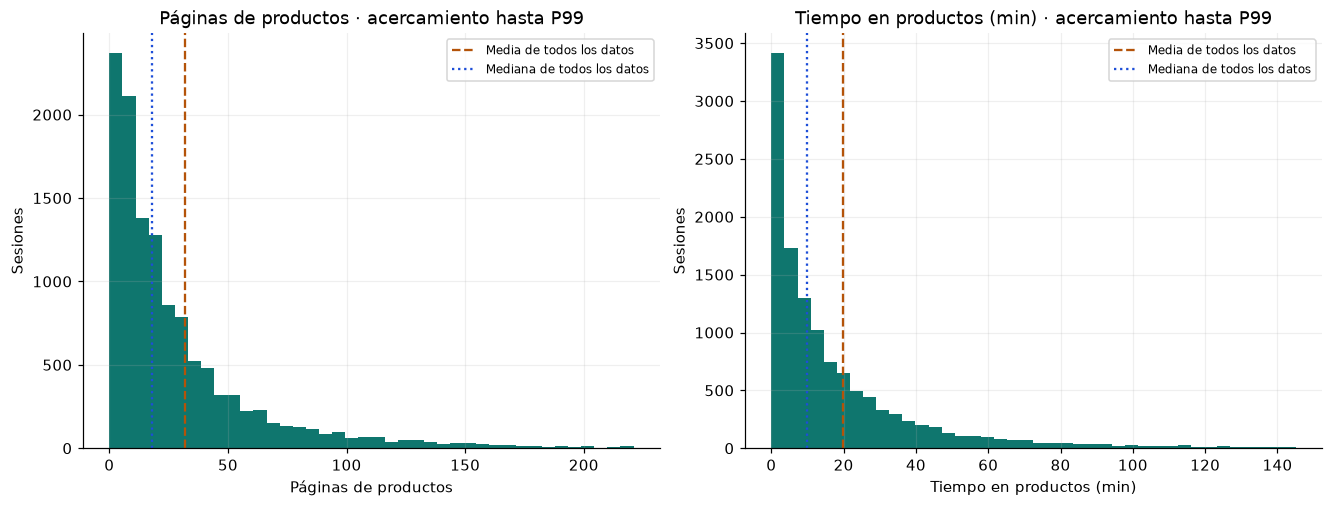

**Figura 11.** Acercamiento de páginas y duración hasta el percentil 99; los valores fuera de la vista permanecen en el análisis principal.

**Tabla 10. Cambios descriptivos en escenarios restringidos por variable**

,variable,escenario,n,excluidas,media,mediana
0,Páginas de productos,Todas las sesiones,12.330,0,"31,731","18,000"
1,Páginas de productos,"Dentro de 1,5 IQR",11.343,987,"21,666","16,000"
2,Páginas de productos,Dentro de 3 IQR,11.917,413,"25,644","17,000"
3,Tiempo en productos (min),Todas las sesiones,12.330,0,"19,912","9,982"
4,Tiempo en productos (min),"Dentro de 1,5 IQR",11.369,961,"13,121","8,608"
5,Tiempo en productos (min),Dentro de 3 IQR,11.928,402,"15,773","9,428"
6,Rebote (%),Todas las sesiones,12.330,0,"2,219","0,311"
7,Rebote (%),"Dentro de 1,5 IQR",10.779,1.551,"0,645","0,000"
8,Rebote (%),Dentro de 3 IQR,11.281,1.049,"0,862","0,103"


**Tabla 11. Diferencias entre grupos e IC individuales en cada escenario**

,variable,escenario,n_con_compra,n_sin_compra,diferencia_con_menos_sin,IC95_diferencia_inferior,IC95_diferencia_superior
0,Páginas de productos,Todas las sesiones,1.908,10.422,"19,496","16,765","22,226"
1,Páginas de productos,"Dentro de 1,5 IQR",1.623,9.720,"8,494","7,449","9,540"
2,Páginas de productos,Dentro de 3 IQR,1.765,10.152,"11,154","9,728","12,580"
3,Tiempo en productos (min),Todas las sesiones,1.908,10.422,"13,437","11,613","15,261"
4,Tiempo en productos (min),"Dentro de 1,5 IQR",1.619,9.750,"6,198","5,488","6,908"
5,Tiempo en productos (min),Dentro de 3 IQR,1.770,10.158,"8,388","7,408","9,367"
6,Rebote (%),Todas las sesiones,1.908,10.422,"-2,020","-2,134","-1,906"
7,Rebote (%),"Dentro de 1,5 IQR",1.883,8.896,"-0,278","-0,316","-0,240"
8,Rebote (%),Dentro de 3 IQR,1.901,9.380,"-0,480","-0,529","-0,432"


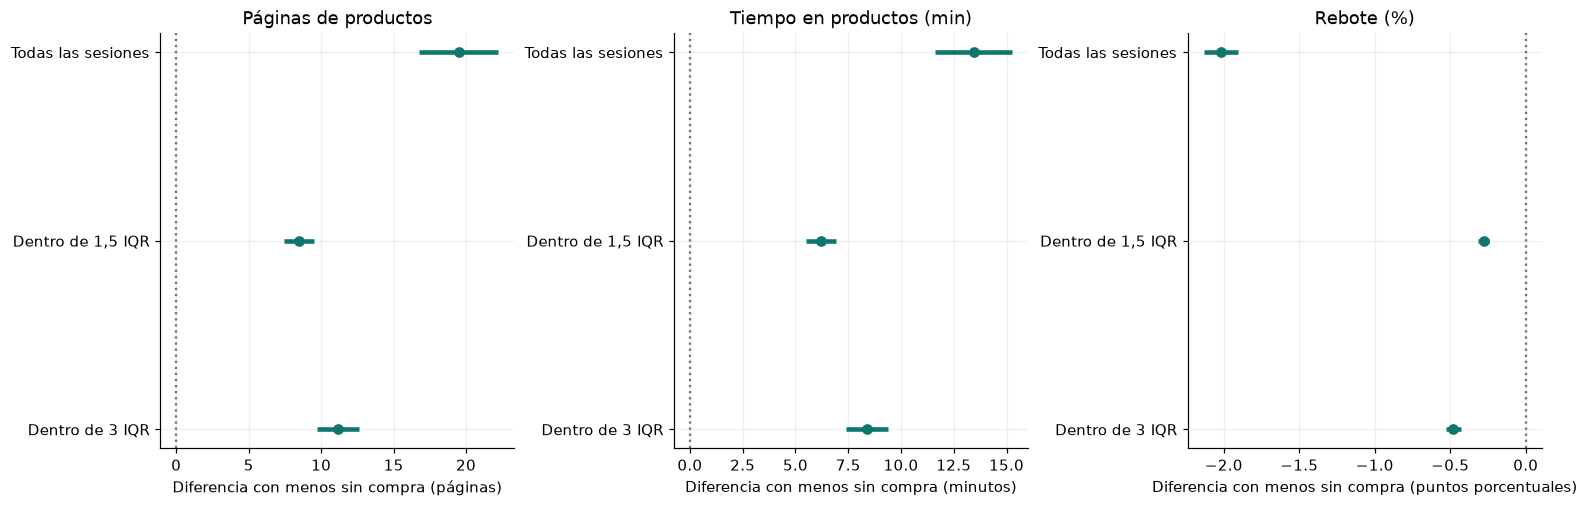

**Figura 12.** Diferencias entre grupos con IC individuales del 95 %: todas las sesiones y escenarios restringidos por IQR.

**Páginas de productos:** con 1,5 IQR se excluyen **987** sesiones; la media cambia **-31,72 %**. La diferencia entre grupos pasa de **19,496** a **8,494** en las unidades del indicador (páginas). La dirección **se mantiene**, pero la magnitud debe compararse: no son resultados intercambiables.

**Tiempo en productos (min):** con 1,5 IQR se excluyen **961** sesiones; la media cambia **-34,10 %**. La diferencia entre grupos pasa de **13,437** a **6,198** en las unidades del indicador (minutos para duración). La dirección **se mantiene**, pero la magnitud debe compararse: no son resultados intercambiables.

**Rebote (%):** con 1,5 IQR se excluyen **1551** sesiones; la media cambia **-70,92 %**. La diferencia entre grupos pasa de **-2,020** a **-0,278** en las unidades del indicador (puntos porcentuales para rebote). La dirección **se mantiene**, pero la magnitud debe compararse: no son resultados intercambiables.

**Decisión metodológica:** se conserva el análisis con todas las sesiones. Los escenarios muestran cuánto influye la cola, sin validar los extremos ni justificar su borrado. Una conclusión sobre diferencias puede mantener dirección y, al mismo tiempo, depender apreciablemente de los extremos en magnitud. Para excluirlos como errores haría falta evidencia sobre su registro.

In [19]:
limites_atipicos=[]
for c in NUMERICAS:
    q1,q3=df[c].quantile([.25,.75]);iqr=q3-q1
    limite=q3+1.5*iqr
    marcada=(df[c]<q1-1.5*iqr)|(df[c]>limite)
    limites_atipicos.append({'variable':c,'IQR':iqr,'límite_superior_1_5':limite,
                             'sesiones_marcadas':int(marcada.sum()),
                             'porcentaje':marcada.mean()*100,
                             'regla_informativa':'IQR cero: cualquier positivo' if iqr==0 else 'Revisar cola y contexto'})
mostrar_tabla(pd.DataFrame(limites_atipicos),'Detección por variable: regla global de 1,5 IQR')

extremos=df.nlargest(8,'ProductRelated_Duration')[
    ['ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','Revenue']].copy()
extremos.insert(0,'fila_CSV',extremos.index+2)
extremos['duración_horas']=extremos.ProductRelated_Duration/3600
extremos['rebote_%']=extremos.BounceRates*100
extremos['salida_%']=extremos.ExitRates*100
mostrar_tabla(extremos[['fila_CSV','ProductRelated','duración_horas','rebote_%','salida_%','Revenue']],
              'Ocho duraciones máximas: filas para investigar, no errores confirmados')

diagnostico_grupo=[]
for c in PRINCIPALES:
    for g in [False,True]:
        x=df.loc[df.Revenue==g,c];q1,q3=x.quantile([.25,.75]);iqr=q3-q1
        flags=(x<q1-1.5*iqr)|(x>q3+1.5*iqr)
        diagnostico_grupo.append({'variable':ETIQUETAS[c],'grupo':'Con compra' if g else 'Sin compra',
                                  'límite_superior':(q3+1.5*iqr)*FACTORES[c],
                                  'marcadas':int(flags.sum()),'porcentaje':flags.mean()*100})
mostrar_tabla(pd.DataFrame(diagnostico_grupo),'Diagnóstico dentro de cada grupo (no usado para filtrar escenarios)')

fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for ax,c in zip(axes,PRINCIPALES[:2]):
    x=df[c]*FACTORES[c];p99=x.quantile(.99)
    ax.hist(x,bins=40,range=(0,p99),color=COLORES[1])
    ax.axvline(x.mean(),color='#b45309',linestyle='--',label='Media de todos los datos')
    ax.axvline(x.median(),color='#1d4ed8',linestyle=':',label='Mediana de todos los datos')
    ax.set(title=f'{ETIQUETAS[c]} · acercamiento hasta P99',xlabel=ETIQUETAS[c],ylabel='Sesiones')
    ax.legend(fontsize=8)
    display(Markdown(f'Acercamiento de **{ETIQUETAS[c]}**: el eje llega hasta **{numero(p99)}**; '
                     f'**{int((x>p99).sum())} sesiones** quedan fuera de esta vista. '
                     'Siguen incluidas en los cálculos principales y en las figuras de rango completo.'))
plt.show()
display(Markdown('**Figura 11.** Acercamiento de páginas y duración hasta el percentil 99; los valores fuera de la vista permanecen en el análisis principal.'))

escenarios=[]
for c in PRINCIPALES:
    q1,q3=df[c].quantile([.25,.75]);iqr=q3-q1;f=FACTORES[c]
    for nombre,k in [('Todas las sesiones',None),('Dentro de 1,5 IQR',1.5),('Dentro de 3 IQR',3)]:
        mascara=np.ones(len(df),dtype=bool) if k is None else df[c].between(q1-k*iqr,q3+k*iqr)
        s=df.loc[mascara]
        n,media,std,se,li,ls=intervalo_media(s[c])
        con=s.loc[s.Revenue,c].to_numpy();sin=s.loc[~s.Revenue,c].to_numpy()
        test=stats.ttest_ind(con,sin,equal_var=False)
        ic=test.confidence_interval(confidence_level=CONFIANZA)
        escenarios.append({'variable':ETIQUETAS[c],'escenario':nombre,'n':n,
                           'excluidas':len(df)-n,'n_con_compra':len(con),'n_sin_compra':len(sin),
                           'media':media*f,'mediana':s[c].median()*f,
                           'IC95_media_inferior':li*f,'IC95_media_superior':ls*f,
                           'diferencia_con_menos_sin':(con.mean()-sin.mean())*f,
                           'IC95_diferencia_inferior':ic.low*f,'IC95_diferencia_superior':ic.high*f})
sensibilidad_extremos=pd.DataFrame(escenarios)
mostrar_tabla(sensibilidad_extremos[['variable','escenario','n','excluidas','media','mediana']],
              'Cambios descriptivos en escenarios restringidos por variable')
mostrar_tabla(sensibilidad_extremos[['variable','escenario','n_con_compra','n_sin_compra',
                                    'diferencia_con_menos_sin','IC95_diferencia_inferior','IC95_diferencia_superior']],
              'Diferencias entre grupos e IC individuales en cada escenario')

fig,axes=plt.subplots(1,3,figsize=(14,4.5),constrained_layout=True)
for ax,c in zip(axes,PRINCIPALES):
    s=sensibilidad_extremos.loc[sensibilidad_extremos.variable==ETIQUETAS[c]].reset_index(drop=True)
    for i,r in s.iterrows():
        ax.hlines(i,r.IC95_diferencia_inferior,r.IC95_diferencia_superior,color=COLORES[1],lw=3)
        ax.plot(r.diferencia_con_menos_sin,i,'o',color=COLORES[1])
    ax.set_yticks(range(3),s.escenario)
    ax.axvline(0,color='#64748b',linestyle=':')
    unidad='puntos porcentuales' if c=='BounceRates' else ('minutos' if 'Duration' in c else 'páginas')
    ax.set(title=ETIQUETAS[c],xlabel=f'Diferencia con menos sin compra ({unidad})')
    ax.invert_yaxis()
plt.show()
display(Markdown('**Figura 12.** Diferencias entre grupos con IC individuales del 95 %: todas las sesiones y escenarios restringidos por IQR.'))

interpretaciones_extremos=[]
for c in PRINCIPALES:
    s=sensibilidad_extremos.loc[sensibilidad_extremos.variable==ETIQUETAS[c]].set_index('escenario')
    base=s.loc['Todas las sesiones'];recorte=s.loc['Dentro de 1,5 IQR']
    cambio=(recorte['media']/base['media']-1)*100
    misma_direccion=np.sign(base.diferencia_con_menos_sin)==np.sign(recorte.diferencia_con_menos_sin)
    interpreta=(f'**{ETIQUETAS[c]}:** con 1,5 IQR se excluyen **{int(recorte.excluidas)}** sesiones; '
                f'la media cambia **{numero(cambio)} %**. La diferencia entre grupos pasa de '
                f'**{numero(base.diferencia_con_menos_sin,3)}** a '
                f'**{numero(recorte.diferencia_con_menos_sin,3)}** en las unidades del indicador '
                f'({"puntos porcentuales para rebote" if c=="BounceRates" else "minutos para duración" if "Duration" in c else "páginas"}). '
                f'La dirección **{"se mantiene" if misma_direccion else "cambia"}**, '
                'pero la magnitud debe compararse: no son resultados intercambiables.')
    display(Markdown(interpreta));interpretaciones_extremos.append(interpreta)
display(Markdown('**Decisión metodológica:** se conserva el análisis con todas las sesiones. '
                 'Los escenarios muestran cuánto influye la cola, sin validar los extremos ni '
                 'justificar su borrado. Una conclusión sobre diferencias puede mantener dirección '
                 'y, al mismo tiempo, depender apreciablemente de los extremos en magnitud. '
                 'Para excluirlos como errores haría falta evidencia sobre su registro.'))

## 9. Síntesis para el informe técnico

Las siguientes salidas reúnen los resultados del notebook que pueden trasladarse al PDF.
El informe debe seleccionar las tablas y figuras pertinentes dentro de sus ocho páginas,
explicar métodos y limitaciones, e incluir el enlace al repositorio. El notebook conserva
el detalle y el código; ambos entregables deben usar las mismas cifras y decisiones.

In [20]:
resumen_final=[]
for c in PRINCIPALES:
    r=estimaciones.loc[c];f=FACTORES[c]
    resumen_final.append({'indicador':ETIQUETAS[c],'estimación':numero(r['media']*f,3),
                         'IC95':f"[{numero(r['IC95_t_inferior']*f,3)}; {numero(r['IC95_t_superior']*f,3)}]",
                         'método':'Media e IC t aproximado'})
for c in PRINCIPALES[:2]:
    r=pruebas.loc[c];f=FACTORES[c]
    resumen_final.append({'indicador':f'Diferencia con menos sin compra · {ETIQUETAS[c]}',
                         'estimación':numero(r['diferencia_con_menos_sin']*f),
                         'IC95':f"[{numero(r['IC95_diferencia_inferior']*f)}; {numero(r['IC95_diferencia_superior']*f)}]",
                         'método':f"Welch · p Holm {r['p_Holm']:.3e} · {r['decisión_Holm']}"})
resumen_estimaciones=pd.DataFrame(resumen_final[:3])
resumen_pruebas=pd.DataFrame(resumen_final[3:])
resumen_pruebas['indicador']=['Páginas de productos: con menos sin compra',
                              'Minutos en productos: con menos sin compra']
mostrar_tabla(resumen_estimaciones,'Tres estimaciones para el informe')
mostrar_tabla(resumen_pruebas,'Dos contrastes y magnitudes para el informe')

paginas=pruebas.loc['ProductRelated']
tiempo=pruebas.loc['ProductRelated_Duration']
display(Markdown(f"""
### Conclusiones preliminares

1. **Contexto:** el **{numero(porcentaje_compra)} %** de las sesiones termina en compra.
   La mayoría de los registros corresponde a sesiones sin compra; los tamaños deben
   considerarse al comparar conteos y porcentajes.
2. **Navegación y compra:** las sesiones con compra registran, en promedio,
   **{numero(paginas['diferencia_con_menos_sin'])} páginas de productos más** y
   **{numero(tiempo['diferencia_con_menos_sin']/60)} minutos más** en esas páginas.
   Las dos diferencias se evalúan con Welch y Holm en la sección 8; las tablas proporcionan
   los intervalos y valores p, sin convertir significancia estadística en causalidad.
3. **Distribución:** media y mediana difieren, por lo que reportar únicamente el promedio
   ocultaría la asimetría y la presencia de sesiones extremas.
4. **Relaciones:** páginas y duración comparten información. Las comparaciones de visitante,
   mes y fin de semana generan nuevas preguntas, no explicaciones causales confirmadas.
5. **Sensibilidad:** las decisiones de los contrastes {"se mantienen" if coinciden else "cambian"}
   al excluir filas idénticas. Esta comprobación aborda una decisión de preparación concreta.

**Respuesta a la pregunta central:** en estos datos existen diferencias de navegación
entre sesiones con y sin compra. Sirven para describir el comportamiento observado y orientar
investigaciones, pero no permiten atribuir una compra al efecto de incrementar páginas o tiempo.
"""))

rebote_si=df.loc[df.Revenue,'BounceRates'].mean()*100
rebote_no=df.loc[~df.Revenue,'BounceRates'].mean()*100
mes=conversion['Month']
mes_mayor=mes.porcentaje_compra.idxmax();mes_menor=mes.porcentaje_compra.idxmin()
fin=conversion['Weekend']
respuestas=pd.DataFrame([
    ('Proporción de compra',f'{numero(porcentaje_compra)} % ({n_compra} de {len(df)} sesiones)',
     'La mayoría de las sesiones no compra; comparar porcentajes con denominadores.',
     'Describe el dataset, no todas las tiendas.'),
    ('Páginas y tiempo promedio',f'{numero(df.ProductRelated.mean())} páginas; {numero(df.ProductRelated_Duration.mean()/60)} minutos',
     'Los promedios superan las medianas por la cola derecha.',
     'No son valores de una sesión típica ni tiempo de atención activa.'),
    ('Diferencia de páginas',f'{numero(paginas.diferencia_con_menos_sin)} páginas más con compra',
     f'Welch con Holm: {paginas["decisión_Holm"]}.',
     'Asociación, no efecto causal; revisar influencia de extremos.'),
    ('Diferencia de duración',f'{numero(tiempo.diferencia_con_menos_sin/60)} minutos más con compra',
     f'Welch con Holm: {tiempo["decisión_Holm"]}.',
     'Depende del contexto y medición; no justifica prolongar visitas.'),
    ('Rebote y salida',f'Rebote medio: {numero(rebote_si,3)} % con compra y {numero(rebote_no,3)} % sin compra. Salida media: {numero(df.loc[df.Revenue,"ExitRates"].mean()*100,3)} % con compra y {numero(df.loc[~df.Revenue,"ExitRates"].mean()*100,3)} % sin compra.',
     'La métrica de rebote es menor en sesiones con compra; rebote y salida se relacionan.',
     'Comparación descriptiva; rebote no equivale a no comprar.'),
    ('Relaciones numéricas',f'Spearman páginas-tiempo: {numero(corr.loc["ProductRelated","ProductRelated_Duration"],3)}; rebote-salida: {numero(corr.loc["BounceRates","ExitRates"],3)}',
     'Las variables comparten información de navegación.',
     'No establece dirección causal ni asociación ajustada.'),
    ('Tipo de visitante',f'Nuevos: {numero(conversion["VisitorType"].loc["New_Visitor","porcentaje_compra"])} %; recurrentes: {numero(conversion["VisitorType"].loc["Returning_Visitor","porcentaje_compra"])} % compra',
     'La conversión observada es distinta; estudiar composición y tráfico.',
     'Comparación exploratoria sin contraste formal ni ajuste por confusión.'),
    ('Mes y fin de semana',f'Mayor conversión mensual: {mes_mayor} ({numero(mes.loc[mes_mayor,"porcentaje_compra"])} %); menor: {mes_menor} ({numero(mes.loc[mes_menor,"porcentaje_compra"])} %). Fin de semana: {numero(fin.loc[True,"porcentaje_compra"])} %; entre semana: {numero(fin.loc[False,"porcentaje_compra"])} %.',
     'Hay heterogeneidad descriptiva que puede orientar investigación temporal.',
     'Faltan enero y abril, tamaños distintos y posibles campañas; sin prueba adicional.')
],columns=['Pregunta','Resultado','Interpretación','Limitación'])
mostrar_tabla(respuestas,'Respuestas explícitas a las preguntas del proyecto')
display(Markdown('**Conclusión sobre valores atípicos:** al restringir cada variable a 1,5 IQR, '
                 'las diferencias de páginas y duración conservan dirección, pero se reducen '
                 'aproximadamente a la mitad; la diferencia de rebote también se atenúa fuertemente. '
                 'La magnitud depende de las colas. Los escenarios cambian las sesiones y el estimando: '
                 'no constituyen un resultado corregido ni demuestran que los valores originales sean erróneos. '
                 'Las cifras principales conservan todas las sesiones y deben comunicarse junto con esta sensibilidad.'))
display(Markdown('**Prioridad propuesta para el equipo de comercio electrónico:** investigar primero '
                 'la exploración del catálogo y las fichas de productos, verificando si el tiempo '
                 'refleja interés o dificultad. Comparar después segmentos y campañas. '
                 'La propuesta es una agenda de investigación, no una intervención validada.'))

**Tabla 12. Tres estimaciones para el informe**

,indicador,estimación,IC95,método
0,Páginas de productos,"31,731","[30,946; 32,517]",Media e IC t aproximado
1,Tiempo en productos (min),"19,912","[19,349; 20,475]",Media e IC t aproximado
2,Rebote (%),"2,219","[2,134; 2,305]",Media e IC t aproximado


**Tabla 13. Dos contrastes y magnitudes para el informe**

,indicador,estimación,IC95,método
0,Páginas de productos: con menos sin compra,"19,50","[16,77; 22,23]",Welch · p Holm 8.835e-43 · Rechazar H₀
1,Minutos en productos: con menos sin compra,"13,44","[11,61; 15,26]",Welch · p Holm 4.348e-45 · Rechazar H₀



### Conclusiones preliminares

1. **Contexto:** el **15,47 %** de las sesiones termina en compra.
   La mayoría de los registros corresponde a sesiones sin compra; los tamaños deben
   considerarse al comparar conteos y porcentajes.
2. **Navegación y compra:** las sesiones con compra registran, en promedio,
   **19,50 páginas de productos más** y
   **13,44 minutos más** en esas páginas.
   Las dos diferencias se evalúan con Welch y Holm en la sección 8; las tablas proporcionan
   los intervalos y valores p, sin convertir significancia estadística en causalidad.
3. **Distribución:** media y mediana difieren, por lo que reportar únicamente el promedio
   ocultaría la asimetría y la presencia de sesiones extremas.
4. **Relaciones:** páginas y duración comparten información. Las comparaciones de visitante,
   mes y fin de semana generan nuevas preguntas, no explicaciones causales confirmadas.
5. **Sensibilidad:** las decisiones de los contrastes se mantienen
   al excluir filas idénticas. Esta comprobación aborda una decisión de preparación concreta.

**Respuesta a la pregunta central:** en estos datos existen diferencias de navegación
entre sesiones con y sin compra. Sirven para describir el comportamiento observado y orientar
investigaciones, pero no permiten atribuir una compra al efecto de incrementar páginas o tiempo.


**Tabla 14. Respuestas explícitas a las preguntas del proyecto**

,Pregunta,Resultado,Interpretación,Limitación
0,Proporción de compra,"15,47 % (1908 de 12330 sesiones)",La mayoría de las sesiones no compra; comparar porcentajes con denominadores.,"Describe el dataset, no todas las tiendas."
1,Páginas y tiempo promedio,"31,73 páginas; 19,91 minutos",Los promedios superan las medianas por la cola derecha.,No son valores de una sesión típica ni tiempo de atención activa.
2,Diferencia de páginas,"19,50 páginas más con compra",Welch con Holm: Rechazar H₀.,"Asociación, no efecto causal; revisar influencia de extremos."
3,Diferencia de duración,"13,44 minutos más con compra",Welch con Holm: Rechazar H₀.,Depende del contexto y medición; no justifica prolongar visitas.
4,Rebote y salida,"Rebote medio: 0,512 % con compra y 2,532 % sin compra. Salida media: 1,956 % con compra y 4,738 % sin compra.",La métrica de rebote es menor en sesiones con compra; rebote y salida se relacionan.,Comparación descriptiva; rebote no equivale a no comprar.
5,Relaciones numéricas,"Spearman páginas-tiempo: 0,883; rebote-salida: 0,602",Las variables comparten información de navegación.,No establece dirección causal ni asociación ajustada.
6,Tipo de visitante,"Nuevos: 24,91 %; recurrentes: 13,93 % compra",La conversión observada es distinta; estudiar composición y tráfico.,Comparación exploratoria sin contraste formal ni ajuste por confusión.
7,Mes y fin de semana,"Mayor conversión mensual: Nov (25,35 %); menor: Feb (1,63 %). Fin de semana: 17,40 %; entre semana: 14,89 %.",Hay heterogeneidad descriptiva que puede orientar investigación temporal.,"Faltan enero y abril, tamaños distintos y posibles campañas; sin prueba adicional."


**Conclusión sobre valores atípicos:** al restringir cada variable a 1,5 IQR, las diferencias de páginas y duración conservan dirección, pero se reducen aproximadamente a la mitad; la diferencia de rebote también se atenúa fuertemente. La magnitud depende de las colas. Los escenarios cambian las sesiones y el estimando: no constituyen un resultado corregido ni demuestran que los valores originales sean erróneos. Las cifras principales conservan todas las sesiones y deben comunicarse junto con esta sensibilidad.

**Prioridad propuesta para el equipo de comercio electrónico:** investigar primero la exploración del catálogo y las fichas de productos, verificando si el tiempo refleja interés o dificultad. Comparar después segmentos y campañas. La propuesta es una agenda de investigación, no una intervención validada.

## 10. Limitaciones y próximos pasos

### Limitaciones
- Datos observacionales: pueden existir variables de confusión como campaña, intención previa
  o características del usuario no registradas.
- Independencia y selección: la fuente describe usuarios distintos; no hay identificadores
  ni diseño de muestreo que permitan verificar todos los supuestos de inferencia.
- Cobertura temporal y contextual: faltan meses; no se extrapola a otros años o tiendas sin validación.
- Medición: tiempos cero y duraciones muy largas no equivalen necesariamente a atención activa.
  Los extremos se conservaron y se contrastaron con escenarios restringidos por IQR; estos cambian el estimando y no prueban que los extremos sean errores.
- Filas idénticas: se desconoce si son sesiones diferentes con atributos iguales o duplicación real.
- Grupos desiguales y categorías pequeñas: se informa n y se evita confundir volumen con proporción.
- Los IC y pruebas cuantifican incertidumbre bajo supuestos; no cubren sesgo de selección ni errores de medición.
- PageValues requiere revisar su definición y disponibilidad temporal antes de un eventual modelo predictivo.

### Próximos pasos del proyecto
1. Revisar con el equipo las preguntas, interpretaciones y decisiones de calidad; contrastar con la fuente
   cualquier duda sobre la medición de tiempos y tasas.
2. Definir una magnitud de diferencia relevante para la decisión empresarial, con conocimiento del contexto.
3. Profundizar la investigación del registro de extremos y evaluar confusión por tipo de visitante o mes,
   definiendo antes los nuevos análisis y su alcance.
4. En fases posteriores, diseñar y validar modelos según las instrucciones de esas evaluaciones,
   evitando información disponible únicamente después de la compra.
5. Elaborar el PDF de avance con los resultados reproducidos aquí, limitaciones y enlace GitHub.

## 11. Revisión antes de entregar
- [ ] El equipo revisó y puede explicar el objetivo, la fuente y las unidades de las variables.
- [ ] Se acordaron las decisiones de preparación y las interpretaciones.
- [x] El notebook se ejecutó desde un kernel reiniciado, en orden y sin errores (versión revisada, verificación automática del 09/10/2026).
- [ ] Las tres estimaciones tienen IC del 95 %, método, interpretación y limitaciones.
- [ ] Las dos pruebas incluyen hipótesis, α, supuestos, método, resultado e implicancias.
- [ ] Las cifras y figuras del PDF coinciden con esta ejecución.
- [ ] Se comprobaron acceso al repositorio y reproducción en otro equipo del grupo.
- [ ] Se entregan PDF (máximo 8 páginas, sin anexos), .ipynb y enlace GitHub en Canvas.

La ejecución automática de este notebook no marca por sí sola los puntos de revisión humana.

## Referencias
1. Sakar, C. y Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI.
   https://doi.org/10.24432/C5F88Q
2. Topal, İ. (2019). *Estimation of Online Purchasing Intention Using Decision Tree*.
   https://dergipark.org.tr/tr/download/article-file/896156
3. SciPy: prueba de medias independientes, Welch e IC de diferencias.
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
4. SciPy: correlación de Spearman.
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html
5. Instrucciones y rúbrica de Sumativa 1, Fase 2, MCDI501, proporcionadas en Canvas.

Referencia para la investigación de atípicos: NIST, https://www.itl.nist.gov/div898/handbook/prc/section1/prc16.htm
